# [GSE155457](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE155457)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-12-18
> - Modified: 2025-01-12

# 1. Experimental Design

> Genome-wide analysis of the FOXA1 transcriptional network identifies novel protein coding and lncRNA targets in colorectal cancer cells.
> - Lazar, S. B., Pongor, L., Li, X. L., Grammatikakis, I., Muys, B. R., Dangelmaier, E. A., … Lal, A. (2020). Genome-Wide Analysis of the FOXA1 Transcriptional Network Identifies Novel Protein-Coding and Long Noncoding RNA Targets in Colorectal Cancer Cells. Molecular and Cellular Biology, 40(21). https://doi.org/10.1128/MCB.00224-20.
> - polyA RNA-seq
> - Illumina HiSeq 4000, PE150
> - hg38

| Sample | Organism | Cell | Source | Treatment | Replicate |
| - | - | - | - | - | - |
| SW1222 Control | Homo sapiens | SW1222 | Human colon adenocarcinoma | Control | rep1~3 |
| SW1222 siFOXA1 | Homo sapiens | SW1222 | Human colon adenocarcinoma | siFOXA1 | rep1~3 |
| LS180 Control | Homo sapiens | LS180 | Human colon adenocarcinoma | Control | rep1~3 |
| LS180 siFOXA1 | Homo sapiens | LS180 | Human colon adenocarcinoma | siFOXA1 | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Hs_Cell_FOXA1_GSE155457/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 78686    26

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, pattern = "LS180|SW1222")) |>
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = factor(Cell), 
        Group = factor(Group, levels = c("Control", "siFOXA1")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Replicate
,<fct>,<fct>,<fct>
LS180_Control_rep1,LS180,Control,rep1
LS180_Control_rep2,LS180,Control,rep2
LS180_Control_rep3,LS180,Control,rep3
LS180_siFOXA1_rep1,LS180,siFOXA1,rep1
LS180_siFOXA1_rep2,LS180,siFOXA1,rep2
LS180_siFOXA1_rep3,LS180,siFOXA1,rep3
SW1222_Control_rep1,SW1222,Control,rep1
SW1222_Control_rep2,SW1222,Control,rep2
SW1222_Control_rep3,SW1222,Control,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("LS180|SW1222")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 78686 12 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "LS180|SW1222")

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = factor(Cell), 
        Group = factor(Group, levels = c("Control", "siFOXA1")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Group, Replicate) |>
    select("sampleName", "fileName", "Cell", "Group", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Group,Replicate
<chr>,<chr>,<fct>,<fct>,<fct>
LS180_Control_rep1,LS180_Control_rep1.tsv,LS180,Control,rep1
LS180_Control_rep2,LS180_Control_rep2.tsv,LS180,Control,rep2
LS180_Control_rep3,LS180_Control_rep3.tsv,LS180,Control,rep3
LS180_siFOXA1_rep1,LS180_siFOXA1_rep1.tsv,LS180,siFOXA1,rep1
LS180_siFOXA1_rep2,LS180_siFOXA1_rep2.tsv,LS180,siFOXA1,rep2
LS180_siFOXA1_rep3,LS180_siFOXA1_rep3.tsv,LS180,siFOXA1,rep3
SW1222_Control_rep1,SW1222_Control_rep1.tsv,SW1222,Control,rep1
SW1222_Control_rep2,SW1222_Control_rep2.tsv,SW1222,Control,rep2
SW1222_Control_rep3,SW1222_Control_rep3.tsv,SW1222,Control,rep3


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 78686 12 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference//Homo_sapiens/hg38/gencode.v48.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "LS180|SW1222")
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = factor(Cell), 
        Group = factor(Group, levels = c("Control", "siFOXA1")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Group,Replicate
,<fct>,<fct>,<fct>
LS180_Control_rep1,LS180,Control,rep1
LS180_Control_rep2,LS180,Control,rep2
LS180_Control_rep3,LS180,Control,rep3
LS180_siFOXA1_rep1,LS180,siFOXA1,rep1
LS180_siFOXA1_rep2,LS180,siFOXA1,rep2
LS180_siFOXA1_rep3,LS180,siFOXA1,rep3
SW1222_Control_rep1,SW1222,Control,rep1
SW1222_Control_rep2,SW1222,Control,rep2
SW1222_Control_rep3,SW1222,Control,rep3


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


transcripts missing from tx2gene: 11088

summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 78241 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(78241): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "LS180|SW1222")

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        Cell = factor(Cell), 
        Group= factor(Group, levels = c("Control", "siFOXA1")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Group, Replicate) |>
    select("names", "files", "Cell", "Group", "Replicate") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files"))

names,Cell,Group,Replicate
<chr>,<fct>,<fct>,<fct>
LS180_Control_rep1,LS180,Control,rep1
LS180_Control_rep2,LS180,Control,rep2
LS180_Control_rep3,LS180,Control,rep3
LS180_siFOXA1_rep1,LS180,siFOXA1,rep1
LS180_siFOXA1_rep2,LS180,siFOXA1,rep2
LS180_siFOXA1_rep3,LS180,siFOXA1,rep3
SW1222_Control_rep1,SW1222,Control,rep1
SW1222_Control_rep2,SW1222,Control,rep2
SW1222_Control_rep3,SW1222,Control,rep3


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Homo_sapiens/hg38/index/salmon_index", 
    source = "GENCODE", organism = "Homo sapiens", 
    release = "48", genome = "GRCh38",
    fasta = "~/reference/Homo_sapiens/hg38/gencode.v48.transcripts.fa", 
    gtf = "~/reference/Homo_sapiens/hg38/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Homo_sapiens/hg38/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


found matching linkedTxome:
[ GENCODE - Homo sapiens - release 48 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

Warning message in checkAssays2Txps(assays, txps):
"

11088 out of 395452 txps were missing from GTF/GFF but were in the indexed FASTA
(e.g. this can occur with transcripts located on haplotype chromosomes).
In order to build a ranged SummarizedExperiment, these txps were removed.
To keep these txps, and

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 78241 12 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(78241): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(2): gene_id tx_ids
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(4): names Cell Group Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "LS180|SW1222")
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell), 
        Group= factor(Group, levels = c("Control", "siFOXA1")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Group, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Group,Replicate
,<fct>,<fct>,<fct>
LS180_Control_rep1,LS180,Control,rep1
LS180_Control_rep2,LS180,Control,rep2
LS180_Control_rep3,LS180,Control,rep3
LS180_siFOXA1_rep1,LS180,siFOXA1,rep1
LS180_siFOXA1_rep2,LS180,siFOXA1,rep2
LS180_siFOXA1_rep3,LS180,siFOXA1,rep3
SW1222_Control_rep1,SW1222,Control,rep1
SW1222_Control_rep2,SW1222,Control,rep2
SW1222_Control_rep3,SW1222,Control,rep3


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


transcripts missing from tx2gene: 26375

summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 78686 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(78686): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310576.1 ENSG00000310577.1
rowData names(0):
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 78686 12 
metadata(0):
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group + Cell)

dds

class: DESeqDataSet 
dim: 78686 12 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(12): LS180_Control_rep1 LS180_Control_rep2 ...
  SW1222_siFOXA1_rep2 SW1222_siFOXA1_rep3
colData names(3): Cell Group Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 19200 
 Remove: 59486 
 Retention rate: 24.4 %


In [29]:
design <- model.matrix(~ group + Cell, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18355 
 Remove: 60331 
 Retention rate: 23.33 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,1.2347361,1.9160327,2.3662228,1.5351014,1.4203290,1.6305047,2.459222,1.8099564,1.746379,1.696053,1.891184,1.670539
ENSG00000310527.1,1.0775879,1.3185601,1.9986542,1.1939678,0.8877056,1.7616947,1.900308,1.5418147,1.705766,2.061868,1.633295,2.549771
ENSG00000225880.7,3.1205148,3.0285678,4.5027153,2.5341357,2.2685810,3.2984922,3.940345,4.7930327,6.416927,4.190248,4.183529,4.572003
ENSG00000225630.1,1.3245351,1.0095226,1.1486519,1.3158012,1.2822414,1.1994517,6.511350,8.2453569,11.777905,10.109805,9.341304,9.202620
ENSG00000237973.1,5.6124367,4.4913454,5.6283941,4.3860041,5.5037747,6.1846729,4.387476,4.7930327,4.264414,6.950491,6.160676,5.451234
ENSG00000229344.1,0.4714447,0.3090375,0.6662181,0.7797341,0.8679788,0.5997259,1.145774,0.9384959,1.177790,1.296982,1.375407,1.289539


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,0.1822489,0.2828093,0.3492580,0.2265832,0.20964265,0.2406649,0.3629848,0.2671522,0.2577681,0.2503399,0.2791416,0.2465741
ENSG00000310527.1,0.1417506,0.1734491,0.2629116,0.1570597,0.11677264,0.2317409,0.2499748,0.2028170,0.2243838,0.2712271,0.2148508,0.3354079
ENSG00000225880.7,0.1320797,0.1281879,0.1905831,0.1072605,0.09602053,0.1396128,0.1667800,0.2028711,0.2716045,0.1773575,0.1770731,0.1935157
ENSG00000225630.1,1.2687118,0.9669757,1.1002412,1.2603460,1.22820059,1.1489001,6.2369251,7.8978514,11.2815180,9.6837217,8.9476089,8.8147706
ENSG00000237973.1,3.6373537,2.9107877,3.6476955,2.8425173,3.56693111,4.0082131,2.8434712,3.1063076,2.7637160,4.5045309,3.9926609,3.5328800
ENSG00000229344.1,0.6912679,0.4531342,0.9768594,1.1433051,1.27269620,0.8793634,1.6800205,1.3760937,1.7269655,1.9017326,2.0167253,1.8908199


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,0.7797606,1.2291110,1.4962465,0.9809770,0.8433417,1.0534550,1.472352,1.0888174,1.0426049,0.9985375,1.1251188,1.0001215
ENSG00000310527.1,0.6064867,0.7538233,1.1263325,0.6799795,0.4697481,1.0143925,1.013956,0.8266098,0.9075739,1.0818507,0.8659858,1.3604375
ENSG00000225880.7,0.5651093,0.5571146,0.8164716,0.4643770,0.3862674,0.6111228,0.676499,0.8268304,1.0985693,0.7074306,0.7137176,0.7849132
ENSG00000225630.1,5.4282444,4.2025513,4.7135131,5.4565841,4.9407539,5.0290450,25.298434,32.1888307,45.6308003,38.6257199,36.0645787,35.7533196
ENSG00000237973.1,15.5625930,12.6505093,15.6269914,12.3064891,14.3489012,17.5450278,11.533788,12.6602040,11.1785110,17.9673431,16.0929735,14.3296057
ENSG00000229344.1,2.9576229,1.9693564,4.1849362,4.9498632,5.1197490,3.8492104,6.814558,5.6084680,6.9851254,7.5854916,8.1286912,7.6692964


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,48.08685,75.36045,87.50370,60.84810,57.74162,61.32229,90.54741,67.23660,65.50552,62.96874,70.59762,60.83524
ENSG00000310527.1,41.96671,51.86095,73.91089,47.32630,36.08852,66.25626,69.96845,57.27562,63.98213,76.55024,60.97067,92.85378
ENSG00000225880.7,121.52859,119.11813,166.51189,100.44766,92.22621,124.05428,145.08164,178.05248,240.69470,155.56984,156.17050,166.49644
ENSG00000225630.1,51.58408,39.70604,42.47752,52.15552,52.12786,45.11065,239.74484,306.30007,441.78140,375.34310,348.70946,335.12744
ENSG00000237973.1,218.57661,176.65137,208.13987,173.85172,223.74880,232.60177,161.54480,178.05248,159.95534,258.04838,229.97710,198.51498
ENSG00000229344.1,18.36044,12.15491,24.63696,30.90697,35.28655,22.55532,42.18686,34.86342,44.17814,48.15257,51.34372,46.96053


,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,0.1855208,0.2907433,0.3375924,0.2347541,0.2227692,0.2365835,0.3493351,0.2594012,0.2527226,0.2429356,0.2723681,0.2347045
ENSG00000310527.1,0.1442954,0.1783151,0.2541301,0.1627235,0.1240842,0.2278109,0.2405747,0.1969325,0.2199917,0.2632050,0.2096373,0.3192620
ENSG00000225880.7,0.1344509,0.1317841,0.1842174,0.1111284,0.1020328,0.1372452,0.1605084,0.1969851,0.2662881,0.1721118,0.1727763,0.1842003
ENSG00000225630.1,1.2914889,0.9941035,1.0634919,1.3057958,1.3051032,1.1294163,6.0023909,7.6687062,11.0606956,9.3973076,8.7304924,8.3904451
ENSG00000237973.1,3.7026551,2.9924479,3.5258583,2.9450222,3.7902712,3.9402393,2.7365449,3.0161824,2.7096195,4.3713010,3.8957777,3.3628142
ENSG00000229344.1,0.7036782,0.4658466,0.9442311,1.1845342,1.3523849,0.8644506,1.6168448,1.3361682,1.6931622,1.8454853,1.9677889,1.7997996


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,1.2786683,1.9941287,2.3380759,1.5884610,1.5071924,1.6408088,2.389087,1.757141,1.709314,1.660326,1.860936,1.599209
ENSG00000310527.1,1.1159287,1.3723037,1.9748797,1.2354697,0.9419953,1.7728279,1.846113,1.496824,1.669562,2.018435,1.607172,2.440898
ENSG00000225880.7,3.2315436,3.1520100,4.4491542,2.6222214,2.4073212,3.3193374,3.827970,4.653169,6.280735,4.101981,4.116615,4.376782
ENSG00000225630.1,1.3716624,1.0506700,1.1349883,1.3615380,1.3606598,1.2070318,6.325652,8.004752,11.527931,9.896844,9.191894,8.809677
ENSG00000237973.1,5.8121287,4.6744093,5.5614428,4.5384601,5.8403706,6.2237576,4.262349,4.653169,4.173906,6.804080,6.062139,5.218471
ENSG00000229344.1,0.4882188,0.3216337,0.6582932,0.8068374,0.9210620,0.6035159,1.113098,0.911110,1.152793,1.269661,1.353408,1.234477


,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,0.1887333,0.2943363,0.3451035,0.2344592,0.2224638,0.2421858,0.3526328,0.2593566,0.2522973,0.2450665,0.2746768,0.2360456
ENSG00000310527.1,0.1467941,0.1805188,0.2597842,0.1625190,0.1239141,0.2332055,0.2428457,0.1968987,0.2196215,0.2655137,0.2114143,0.3210863
ENSG00000225880.7,0.1367791,0.1334128,0.1883160,0.1109888,0.1018929,0.1404951,0.1620236,0.1969512,0.2658400,0.1736215,0.1742409,0.1852528
ENSG00000225630.1,1.3138529,1.0063889,1.0871536,1.3041552,1.3033140,1.1561607,6.0590537,7.6673870,11.0420795,9.4797355,8.8044961,8.4383883
ENSG00000237973.1,3.7667717,3.0294292,3.6043051,2.9413222,3.7850749,4.0335435,2.7623780,3.0156635,2.7050590,4.4096437,3.9288002,3.3820294
ENSG00000229344.1,0.7158634,0.4716036,0.9652393,1.1830460,1.3505308,0.8849207,1.6321079,1.3359384,1.6903125,1.8616729,1.9844688,1.8100837


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,0.3676982,1.00349417,1.2323082,0.6790344,0.60184767,0.7226748,1.2646336,0.8265265,0.7900960,0.7455415,0.9069164,0.6899584
ENSG00000310527.1,0.1731952,0.46782697,0.9900323,0.3197064,-0.07026678,0.8337061,0.8950601,0.5975010,0.7565435,1.0248252,0.6971240,1.2956795
ENSG00000225880.7,1.6974037,1.66117086,2.1572067,1.3977089,1.27368762,1.7349880,1.9416863,2.2232491,2.6554916,2.0420345,2.0463908,2.1344872
ENSG00000225630.1,0.4681001,0.08595633,0.1970327,0.4585341,0.45536158,0.2826909,2.6643068,3.0037860,3.5295469,3.3093394,3.2025731,3.1413846
ENSG00000237973.1,2.5419491,2.22808918,2.4784004,2.1862048,2.54864305,2.6399701,2.0962360,2.2232491,2.0682517,2.7698474,2.6031780,2.3875002
ENSG00000229344.1,-1.0004529,-1.58920397,-0.5785357,-0.2872824,-0.10232799,-0.7061685,0.1720675,-0.1087678,0.2297956,0.3628217,0.4515468,0.3202018


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,5.682462,6.202321,6.379362,5.952273,5.890925,5.960368,6.418561,6.067975,6.038047,5.992473,6.124829,5.952399
ENSG00000310527.1,5.501341,5.738583,6.148470,5.636640,5.333505,6.021322,6.083287,5.853089,5.978434,6.186525,5.924207,6.415474
ENSG00000225880.7,6.954652,6.929276,7.352067,6.718026,6.610493,6.979879,7.177481,7.435777,7.818144,7.265208,7.270351,7.351341
ENSG00000225630.1,5.871493,5.559196,5.640643,5.889012,5.880543,5.701936,7.808630,8.126111,8.603710,8.392305,8.297346,8.245349
ENSG00000237973.1,7.757845,7.483936,7.694804,7.463833,7.788132,7.838470,7.370354,7.494918,7.359825,7.971301,7.823087,7.633870
ENSG00000229344.1,4.459185,4.095393,4.737924,4.965658,5.102586,4.647837,5.288547,5.087885,5.330330,5.426484,5.498848,5.402466


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,LS180_Control_rep1,LS180_Control_rep2,LS180_Control_rep3,LS180_siFOXA1_rep1,LS180_siFOXA1_rep2,LS180_siFOXA1_rep3,SW1222_Control_rep1,SW1222_Control_rep2,SW1222_Control_rep3,SW1222_siFOXA1_rep1,SW1222_siFOXA1_rep2,SW1222_siFOXA1_rep3
ENSG00000310526.1,6.990520,7.304944,7.421633,7.148514,7.112074,7.153974,7.449208,7.219980,7.201049,7.172734,7.255879,7.148365
ENSG00000310527.1,6.905683,7.039655,7.290225,6.980341,6.817037,7.209297,7.249242,7.106504,7.184129,7.316890,7.149928,7.469699
ENSG00000225880.7,7.699933,7.682103,7.994581,7.534874,7.464157,7.718354,7.862376,8.060707,8.372381,7.928720,7.932421,7.994490
ENSG00000225630.1,7.036125,6.872505,6.913033,7.043398,7.043047,6.950119,8.368147,8.637379,9.064018,8.870829,8.785303,8.739603
ENSG00000237973.1,8.270249,8.052850,8.219285,8.037012,8.294820,8.335884,7.965086,8.060707,7.955508,8.447537,8.323837,8.170540
ENSG00000229344.1,6.483849,6.325232,6.616697,6.731681,6.804309,6.574952,6.908857,6.797527,6.937135,6.991395,7.033051,6.975411


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


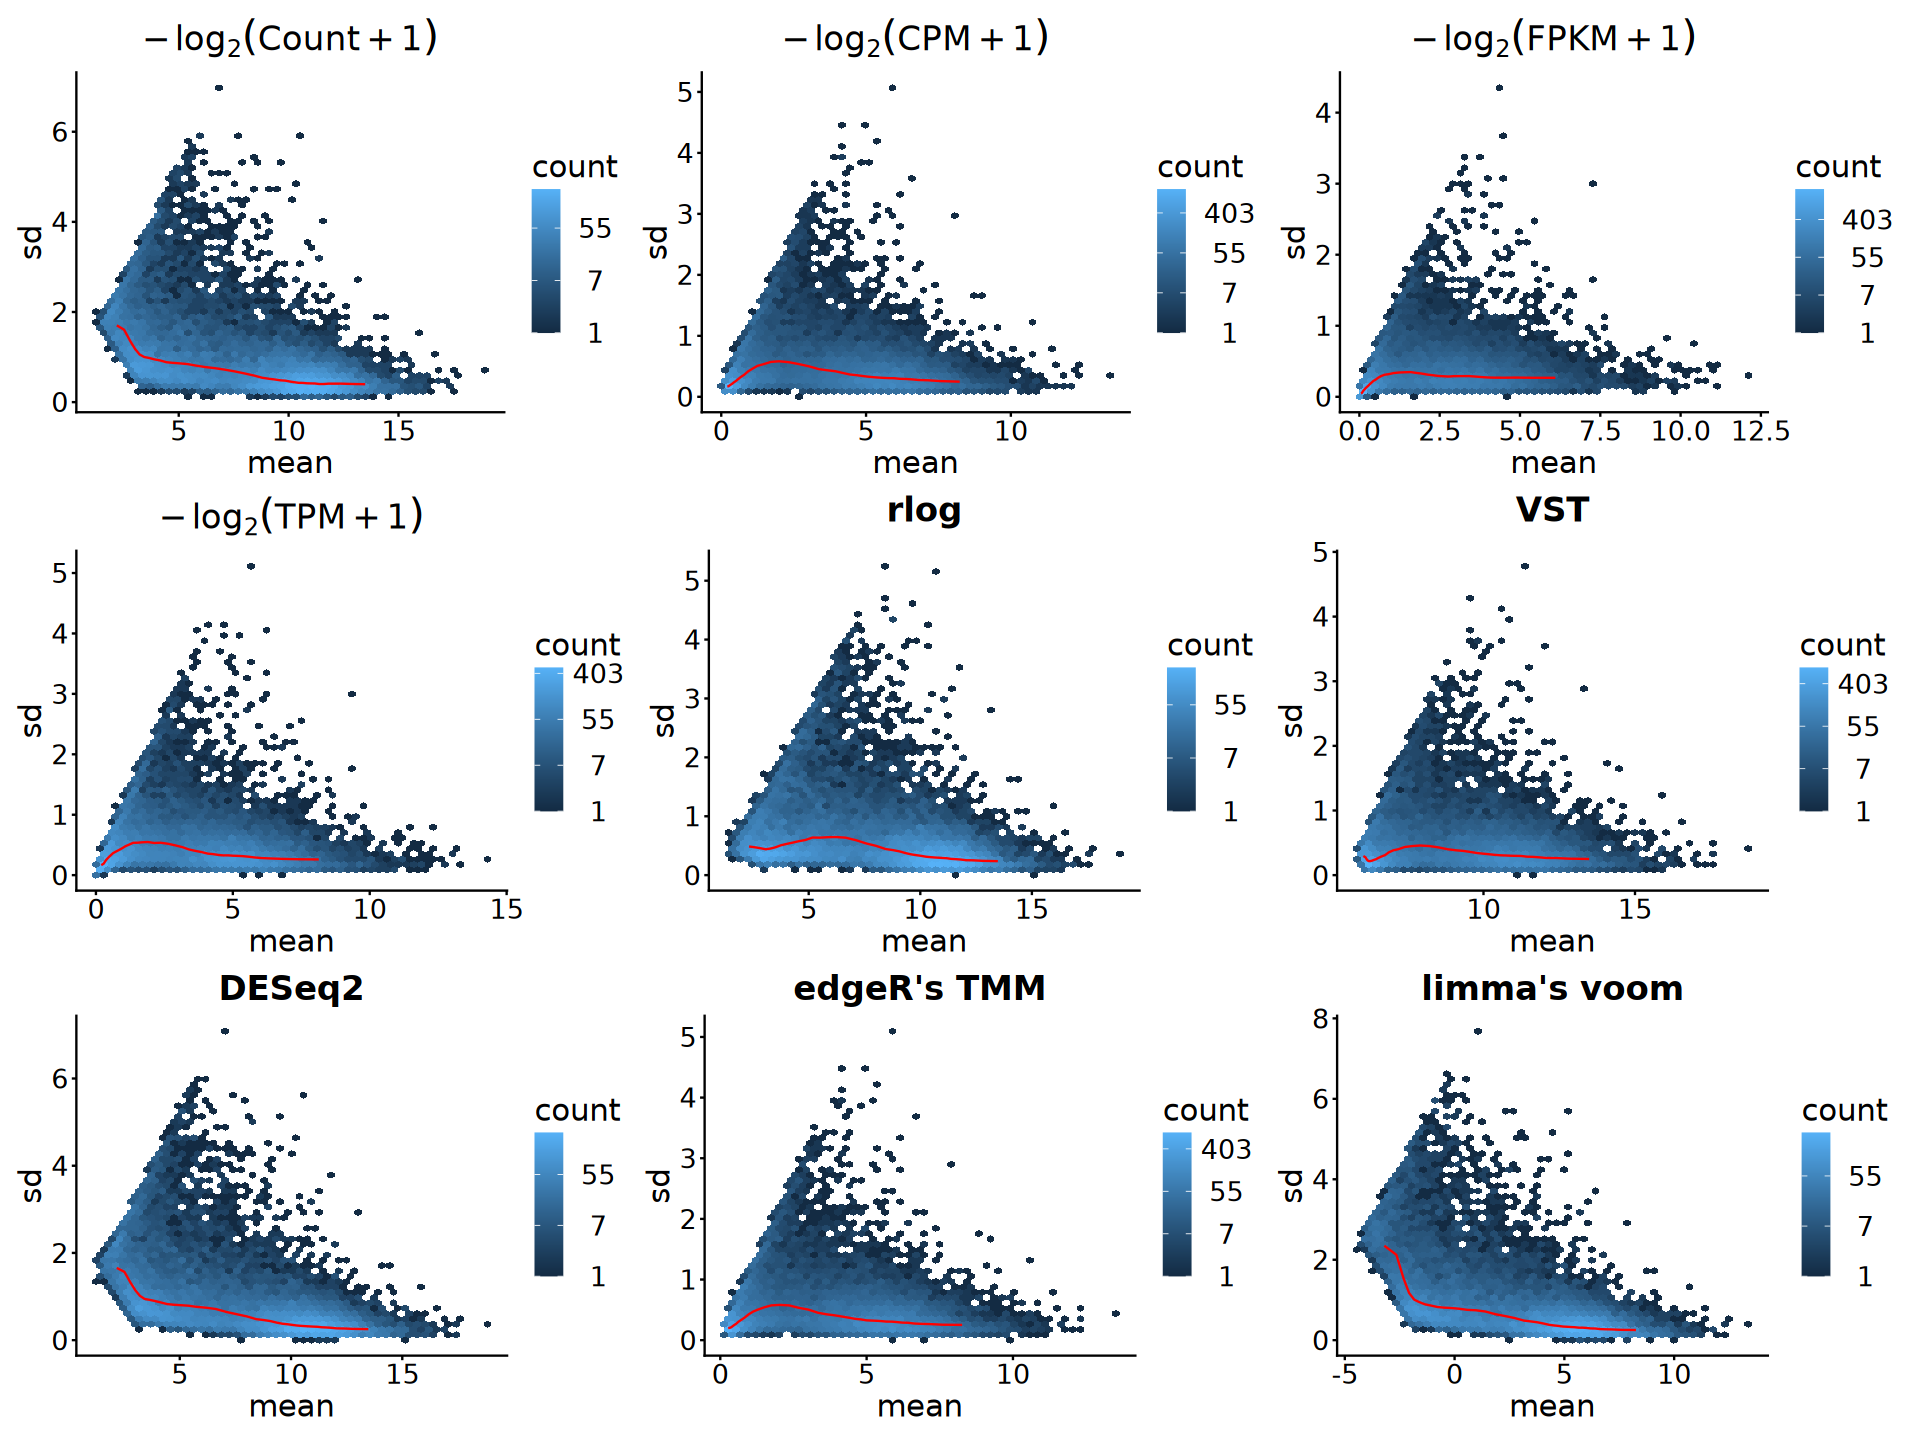

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

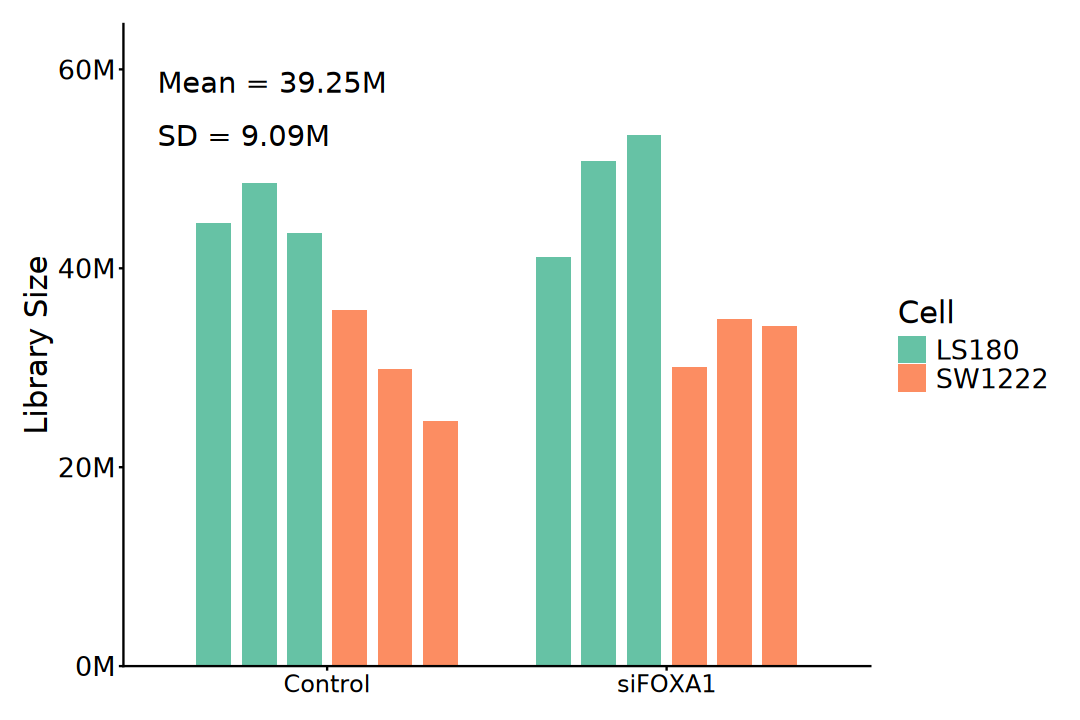

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_col(
        aes(fill = Cell, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = TRUE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14),
        axis.text.y = element_text(size = 16))

## 2). PCA

In [45]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [46]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [47]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
pca_res <- plotPCA(
    rld, intgroup = c("Cell", "Group", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [49]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [51]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

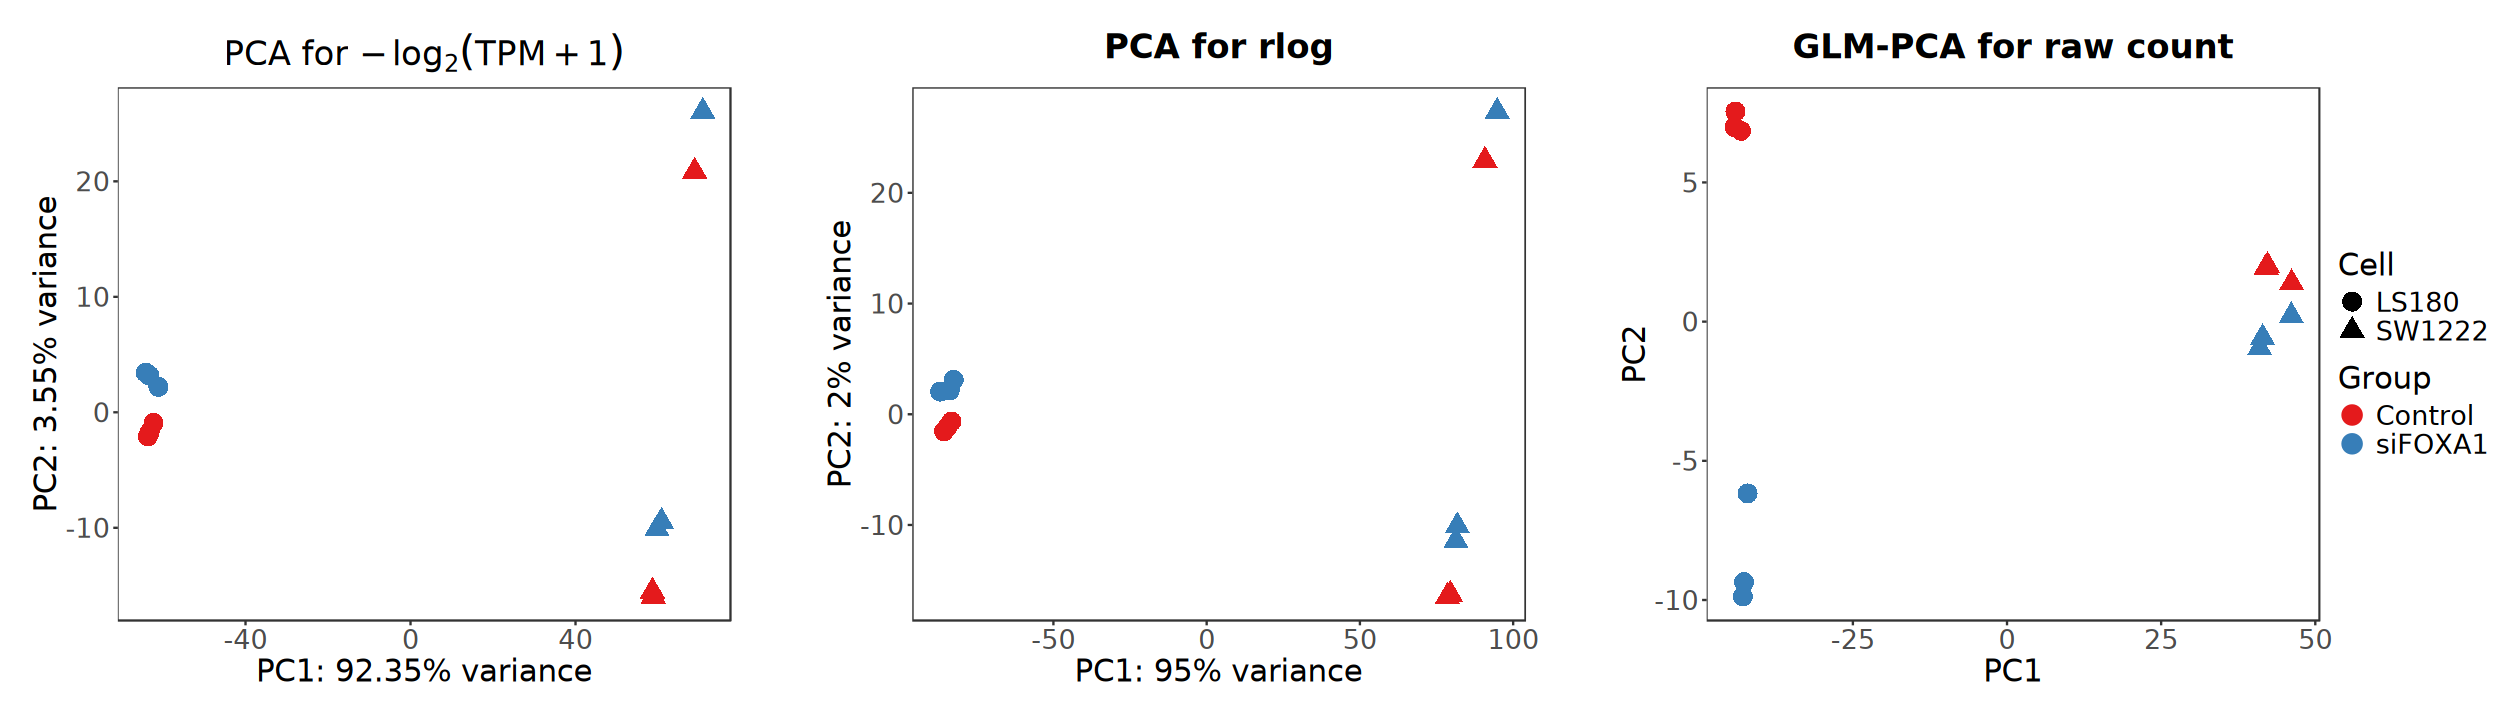

In [52]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [53]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

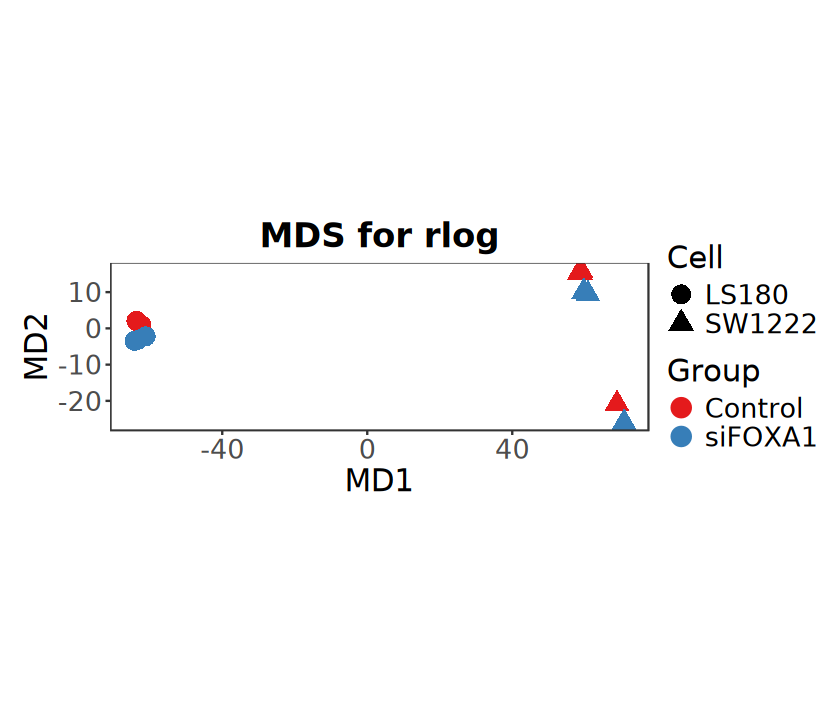

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [55]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

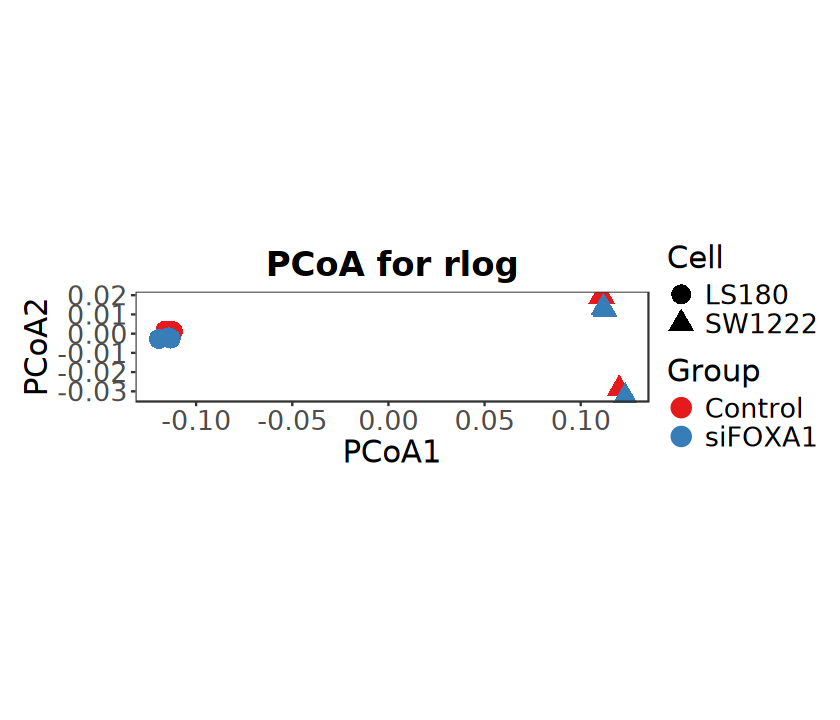

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [57]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Group, Cell)

In [58]:
cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Cell = cell_colors,
    Group = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [59]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

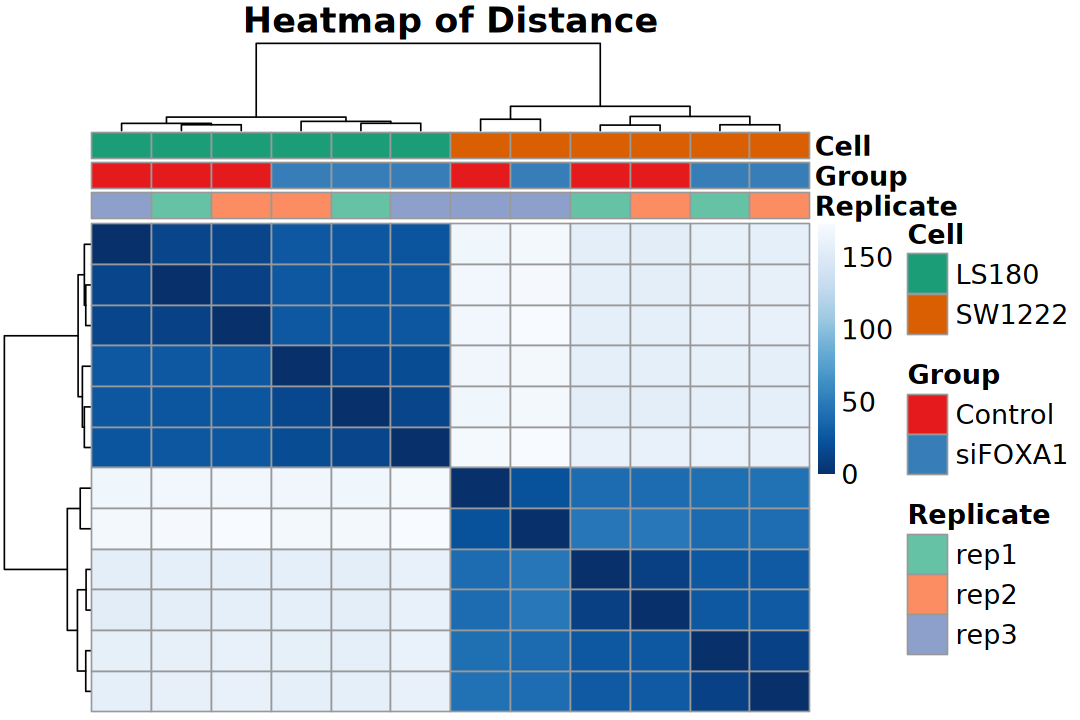

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [61]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

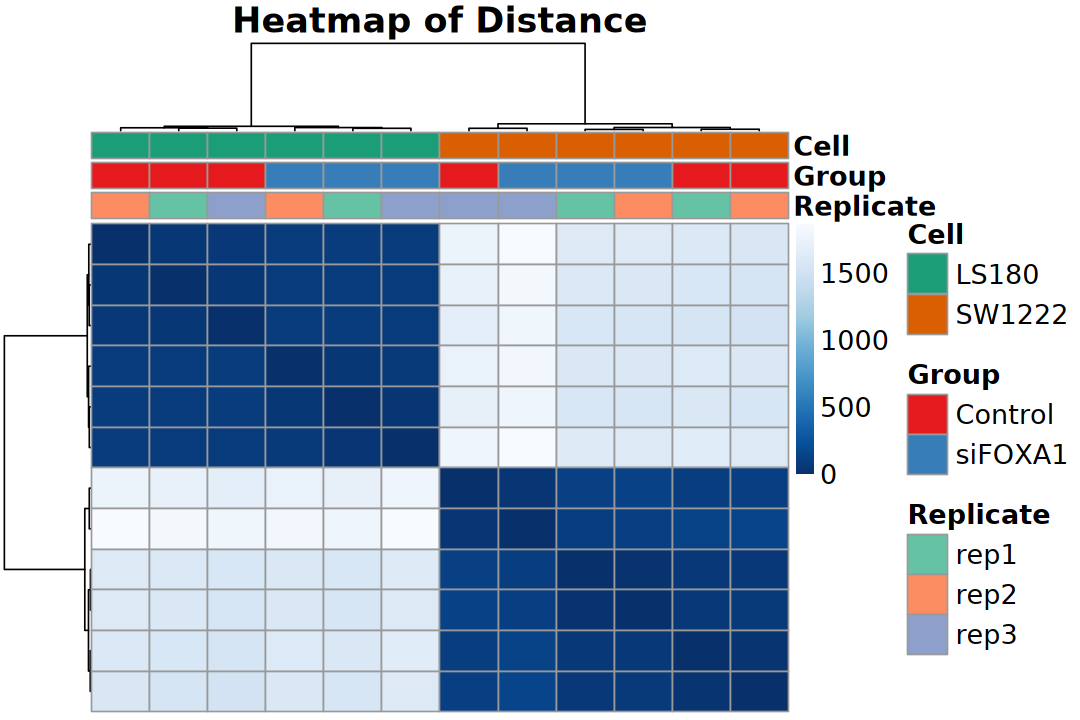

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [63]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

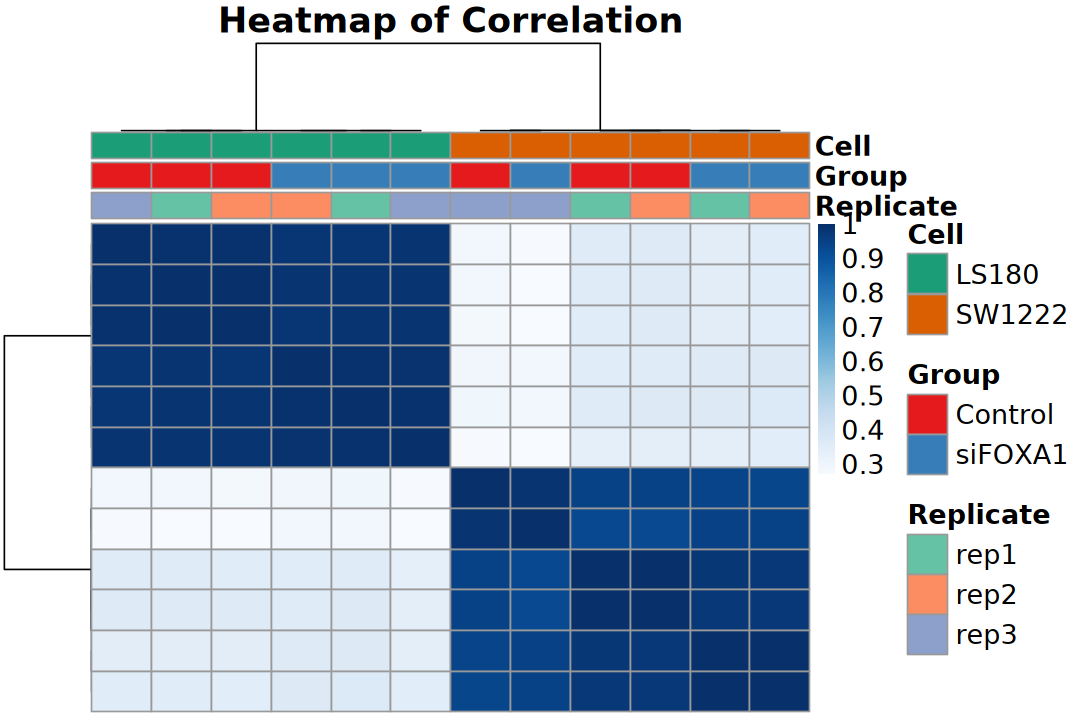

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

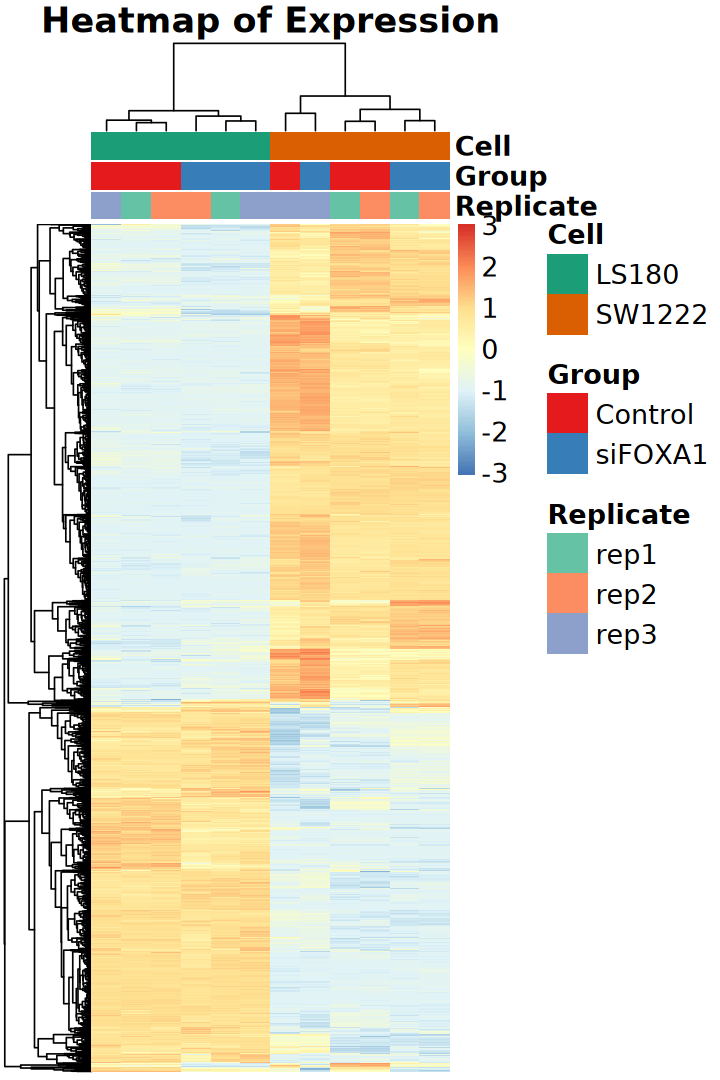

In [65]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [66]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [67]:
design(dds) <- ~ Cell + Group
design(dds)

~Cell + Group

In [68]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [69]:
resultsNames(dds)

[1] "Intercept"                "Cell_SW1222_vs_LS180"    
[3] "Group_siFOXA1_vs_Control"

### a). Standard

In [70]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_siFOXA1_vs_Control", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "siFOXA1", "Control"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 19200 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 14, 0.073%
LFC < -1.00 (down) : 18, 0.094%
outliers [1]       : 19, 0.099%
low counts [2]     : 373, 1.9%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [71]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
   14    18 19168 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSG00000310526.1,67.37951,-0.22116882,0.1780556,-1.2421336,0.9999939,1,NS,WASH7P,lncRNA,6775
ENSG00000310527.1,61.58421,0.05150749,0.2184901,0.2357429,0.9999937,1,NS,WASH9P,lncRNA,7602
ENSG00000225880.7,147.16270,-0.29337244,0.1558440,-1.8824754,0.9999971,1,NS,LINC00115,lncRNA,23626
ENSG00000225630.1,194.18066,0.12779745,0.1630314,0.7838822,1.0000000,1,NS,MTND2P28,unprocessed_pseudogene,1044
ENSG00000237973.1,201.63860,0.25323619,0.1305748,1.9393956,1.0000000,1,NS,MTCO1P12,unprocessed_pseudogene,1543
ENSG00000229344.1,34.29887,0.46608578,0.2282291,2.0421837,0.9903421,1,NS,MTCO2P12,unprocessed_pseudogene,682


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [72]:
res_lfc <- lfcShrink(dds, coef = "Group_siFOXA1_vs_Control", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 19200 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1836, 9.6%
LFC < 0 (down)     : 1979, 10%
outliers [1]       : 19, 0.099%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [73]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  163   172 18865 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSG00000310526.1,67.37951,-0.12991835,0.1483144,0.21418728,0.4781015,NS,WASH7P,lncRNA,6775
ENSG00000310527.1,61.58421,0.02225403,0.1449070,0.81363220,0.9275764,NS,WASH9P,lncRNA,7602
ENSG00000225880.7,147.16270,-0.20677299,0.1480079,0.05977150,0.2165812,NS,LINC00115,lncRNA,23626
ENSG00000225630.1,194.18066,0.07649916,0.1301017,0.43310923,0.6995164,NS,MTND2P28,unprocessed_pseudogene,1044
ENSG00000237973.1,201.63860,0.19361948,0.1246803,0.05245319,0.1981301,NS,MTCO1P12,unprocessed_pseudogene,1543
ENSG00000229344.1,34.29887,0.27407531,0.2290621,0.04113331,0.1678677,NS,MTCO2P12,unprocessed_pseudogene,682


### Evaluate DEGs

In [74]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [75]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [76]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

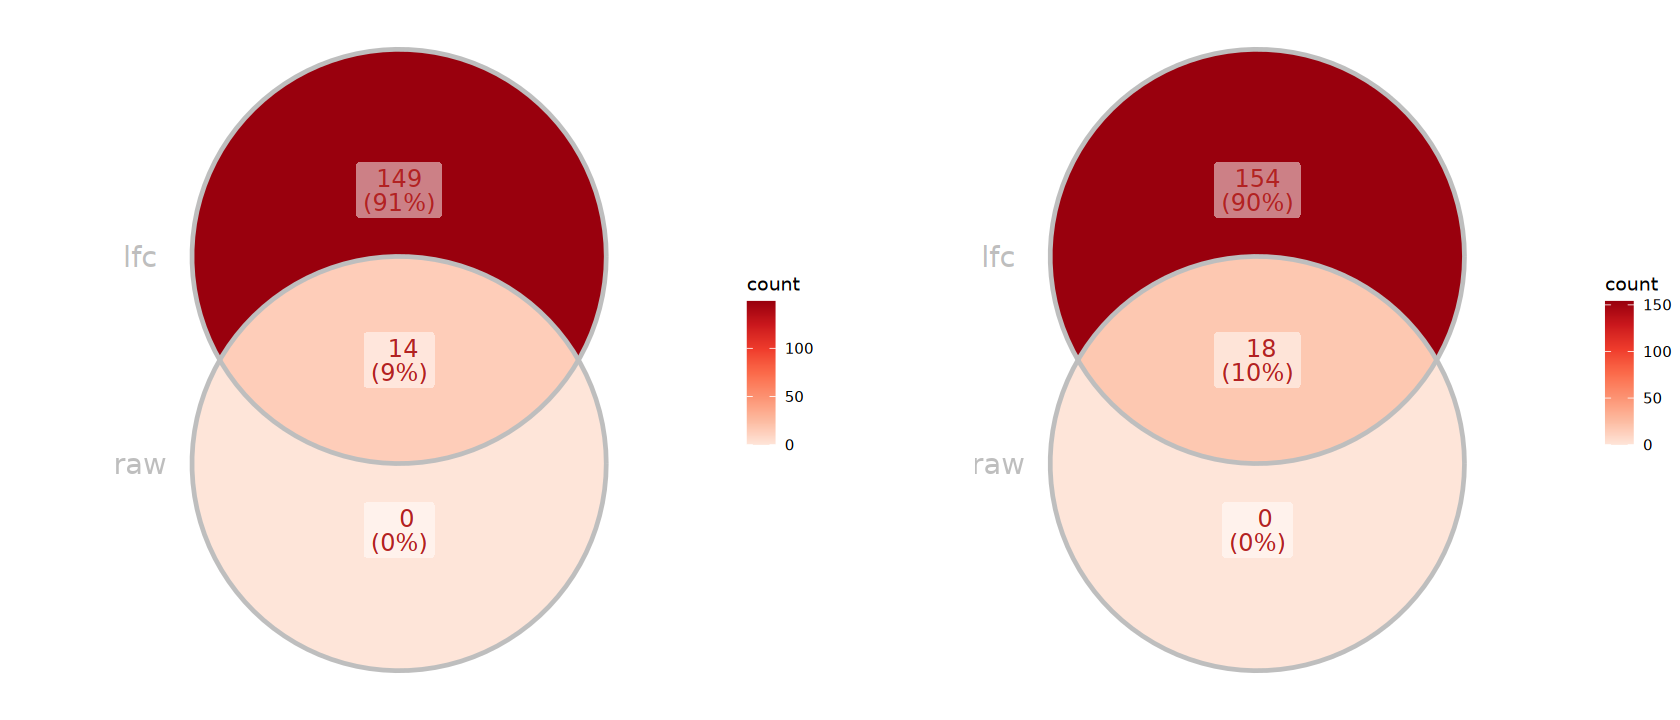

In [77]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [78]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [79]:
# exact test
et <- exactTest(dgel_classic, pair = c("Control", "siFOXA1"))

In [80]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)


   Up  Down    NS 
   34    48 18273 

,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000147140.17,NONO,protein_coding,11222,-1.520541,8.491368,4.280418e-25,6.946338e-21,Down
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.554305,6.008816,7.568879e-25,6.946338e-21,Down
ENSG00000105552.15,BCAT2,protein_coding,4553,-1.664340,5.545811,3.685756e-23,2.255068e-19,Down
ENSG00000179051.14,RCC2,protein_coding,4079,-1.365194,7.747229,1.020532e-22,4.682965e-19,Down
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.209746,5.023773,4.028466e-16,1.478850e-12,Down
ENSG00000104904.13,OAZ1,protein_coding,3578,-1.334522,8.419311,1.268307e-15,3.879963e-12,Down


### b). Negative binomial GLM framework

In [81]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept
design

,(Intercept),groupsiFOXA1,CellSW1222
LS180_Control_rep1,1,0,0
LS180_Control_rep2,1,0,0
LS180_Control_rep3,1,0,0
LS180_siFOXA1_rep1,1,1,0
LS180_siFOXA1_rep2,1,1,0
LS180_siFOXA1_rep3,1,1,0
SW1222_Control_rep1,1,0,1
SW1222_Control_rep2,1,0,1
SW1222_Control_rep3,1,0,1
SW1222_siFOXA1_rep1,1,1,1


In [82]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [83]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [84]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
  292   253 17810 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.258579,5.023856,366.6431,1.007189e-81,1.848695e-77,Down
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.554707,6.008465,261.1665,9.555589e-59,8.003298e-55,Down
ENSG00000180785.10,OR51E1,protein_coding,3612,-2.888732,4.265299,260.5408,1.308085e-58,8.003298e-55,Down
ENSG00000105552.15,BCAT2,protein_coding,4553,-1.654892,5.545087,240.4296,3.169860e-54,1.454569e-50,Down
ENSG00000147140.17,NONO,protein_coding,11222,-1.527872,8.491298,239.5974,4.813810e-54,1.767150e-50,Down
ENSG00000179051.14,RCC2,protein_coding,4079,-1.360514,7.747118,224.5729,9.098199e-51,2.783291e-47,Down


### c). Quasi-likelihood pipeline (edgeR v3)

In [85]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept

In [86]:
dgel_nbglm <- estimateDisp(dgel, design)

In [87]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [88]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
  264   252 17839 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.251799,5.023856,474.8651,7.868725e-12,1.444304e-07,Down
ENSG00000102891.4,MT4,protein_coding,270,2.559817,4.027390,278.1688,1.856948e-11,1.704214e-07,Up
ENSG00000124784.9,RIOK1,protein_coding,2940,-1.215047,5.093149,354.0917,5.273292e-11,2.500211e-07,Down
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.554620,6.008465,352.3013,5.448567e-11,2.500211e-07,Down
ENSG00000180785.10,OR51E1,protein_coding,3612,-2.914597,4.265299,239.0629,9.775043e-11,2.880553e-07,Down
ENSG00000147140.17,NONO,protein_coding,11222,-1.527675,8.491298,316.9626,1.076293e-10,2.880553e-07,Down


### d). Quasi-likelihood pipeline (edgeR v4)

In [89]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept

In [90]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [91]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)


   Up  Down    NS 
  264   250 17841 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.250875,5.023831,475.8639,7.739455e-12,1.420577e-07,Down
ENSG00000102891.4,MT4,protein_coding,270,2.559731,4.024419,283.7265,1.714489e-11,1.573472e-07,Up
ENSG00000124784.9,RIOK1,protein_coding,2940,-1.215195,5.093212,354.5816,5.212941e-11,2.480428e-07,Down
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.554599,6.008569,352.5941,5.405454e-11,2.480428e-07,Down
ENSG00000180785.10,OR51E1,protein_coding,3612,-2.916032,4.263047,251.1461,6.807438e-11,2.499011e-07,Down
ENSG00000147140.17,NONO,protein_coding,11222,-1.527633,8.491318,316.8977,1.075043e-10,2.875140e-07,Down


### Evaluate DEGs

In [92]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [93]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [94]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

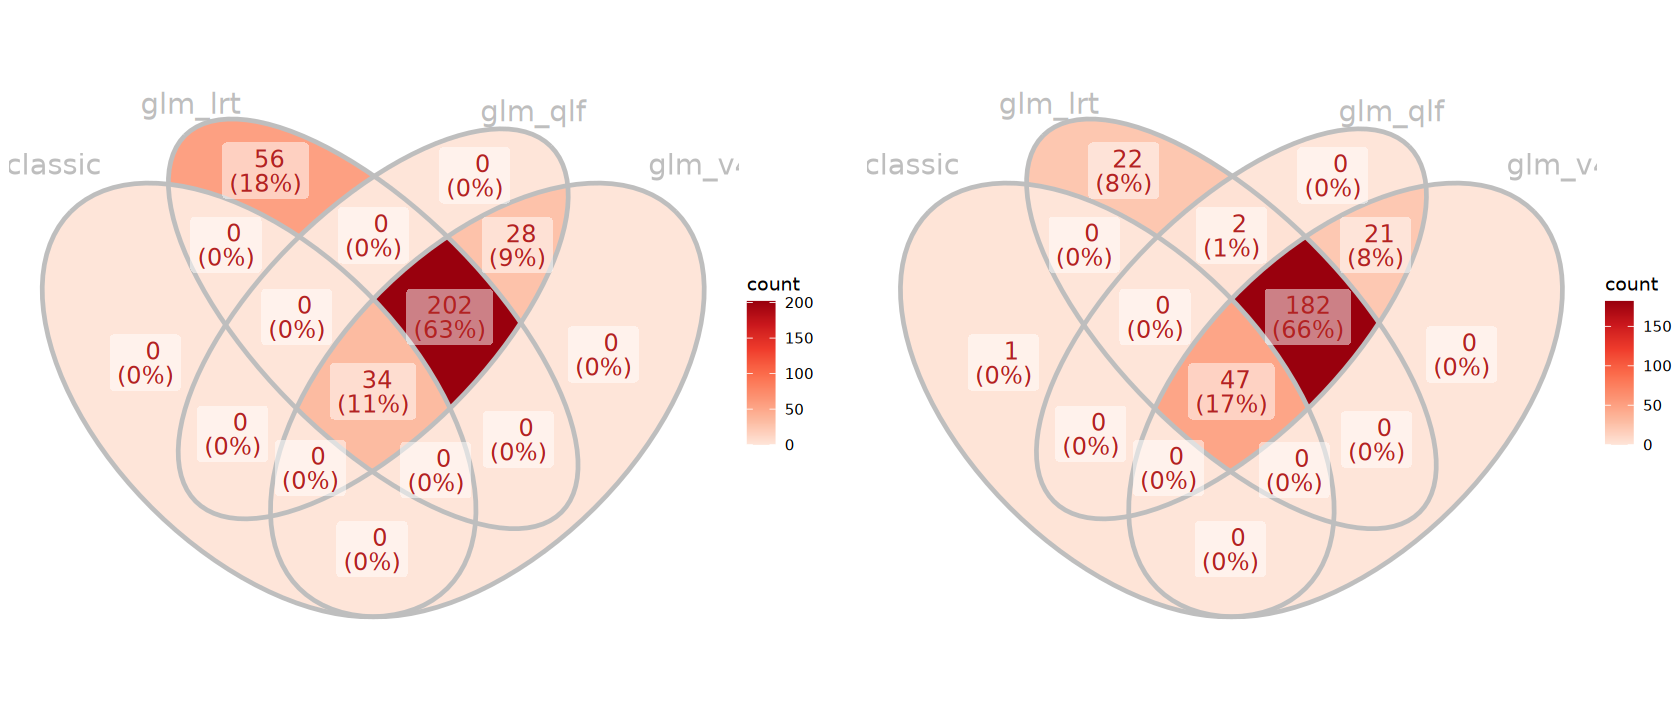

In [95]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [96]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept
design

,(Intercept),groupsiFOXA1,CellSW1222
LS180_Control_rep1,1,0,0
LS180_Control_rep2,1,0,0
LS180_Control_rep3,1,0,0
LS180_siFOXA1_rep1,1,1,0
LS180_siFOXA1_rep2,1,1,0
LS180_siFOXA1_rep3,1,1,0
SW1222_Control_rep1,1,0,1
SW1222_Control_rep2,1,0,1
SW1222_Control_rep3,1,0,1
SW1222_siFOXA1_rep1,1,1,1


In [97]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)

In [98]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_trend_result <- topTable(efit, coef = "groupsiFOXA1", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)
head(limma_trend_result)


   Up  Down    NS 
  184   181 17990 

,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSG00000106785.15,-2.264979,4.592589,-22.30568,5.588363e-12,1.025744e-07,16.87675,Down,TRIM14,protein_coding,5481
ENSG00000163882.10,-1.558560,5.804152,-19.31972,3.625228e-11,2.439977e-07,15.41486,Down,POLR2H,protein_coding,3154
ENSG00000124784.9,-1.210764,4.967772,-19.01951,4.440240e-11,2.439977e-07,15.24991,Down,RIOK1,protein_coding,2940
ENSG00000147140.17,-1.526835,8.292788,-18.43345,6.654861e-11,2.439977e-07,14.91726,Down,NONO,protein_coding,11222
ENSG00000105552.15,-1.660907,5.310312,-18.24134,7.618595e-11,2.439977e-07,14.80506,Down,BCAT2,protein_coding,4553
ENSG00000179051.14,-1.359550,7.586717,-18.17665,7.975953e-11,2.439977e-07,14.76691,Down,RCC2,protein_coding,4079


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [100]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept

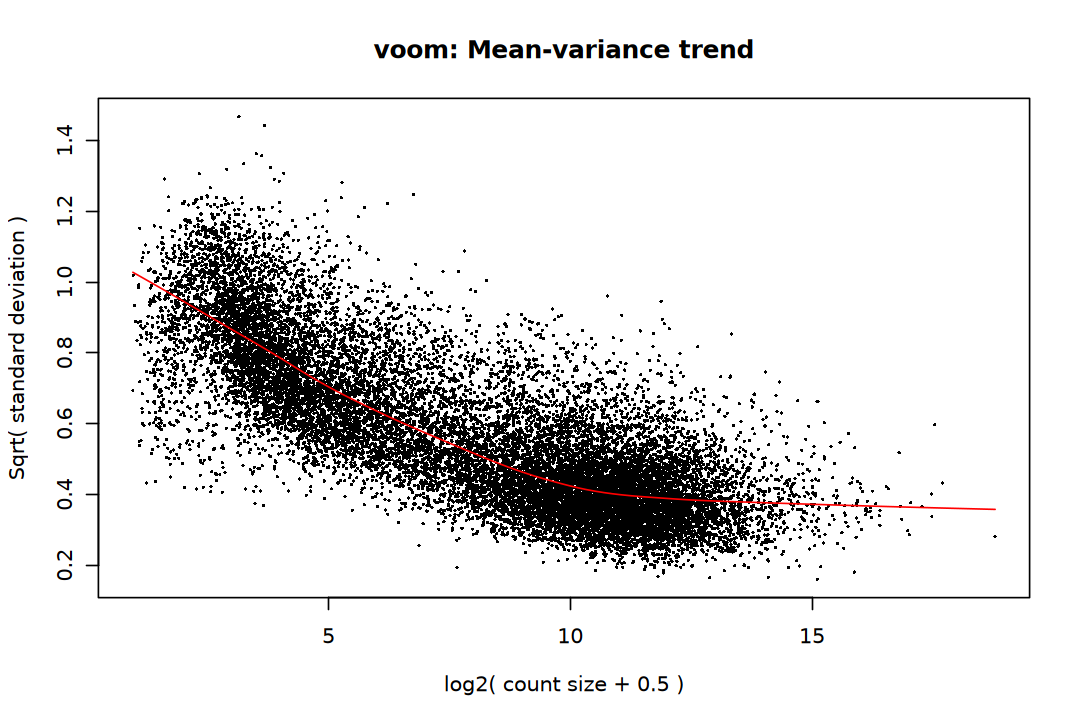

In [101]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [102]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [103]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupsiFOXA1", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
  225   219 17911 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.225750,4.589465,-22.08274,6.634202e-12,1.217708e-07,17.21719,Down
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.559113,5.803014,-19.37904,3.614411e-11,2.440110e-07,15.99112,Down
ENSG00000124784.9,RIOK1,protein_coding,2940,-1.221738,4.965859,-19.23207,3.988194e-11,2.440110e-07,15.81543,Down
ENSG00000147140.17,NONO,protein_coding,11222,-1.523421,8.292587,-18.41734,6.972434e-11,2.591906e-07,15.44236,Down
ENSG00000105552.15,BCAT2,protein_coding,4553,-1.655368,5.308678,-18.39941,7.060489e-11,2.591906e-07,15.32125,Down
ENSG00000179051.14,RCC2,protein_coding,4079,-1.358094,7.586398,-18.02364,9.209100e-11,2.817217e-07,15.16585,Down


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [104]:
design <- model.matrix(~ group + Cell, data = dgel$samples) # include intercept

In [105]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.1863768/2.2971985

Final sample weights (min/max) 0.1842699/2.2970765



In [106]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupsiFOXA1", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)


   Up  Down    NS 
  409   311 17635 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000163882.10,POLR2H,protein_coding,3154,-1.568802,5.803014,-28.20143,5.949965e-15,1.092116e-10,24.45765,Down
ENSG00000147140.17,NONO,protein_coding,11222,-1.532866,8.292587,-26.12304,1.949918e-14,1.456013e-10,23.45765,Down
ENSG00000105552.15,BCAT2,protein_coding,4553,-1.750661,5.308678,-25.78895,2.379754e-14,1.456013e-10,23.07734,Down
ENSG00000135074.16,ADAM19,protein_coding,7704,1.483087,7.808447,25.18634,3.430274e-14,1.504760e-10,22.90011,Up
ENSG00000106785.15,TRIM14,protein_coding,5481,-2.280172,4.589465,-24.89768,4.099047e-14,1.504760e-10,22.32511,Down
ENSG00000104904.13,OAZ1,protein_coding,3578,-1.378749,8.256750,-24.18701,6.409566e-14,1.616389e-10,22.28686,Down


### Evaluate DEGs

In [107]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [109]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

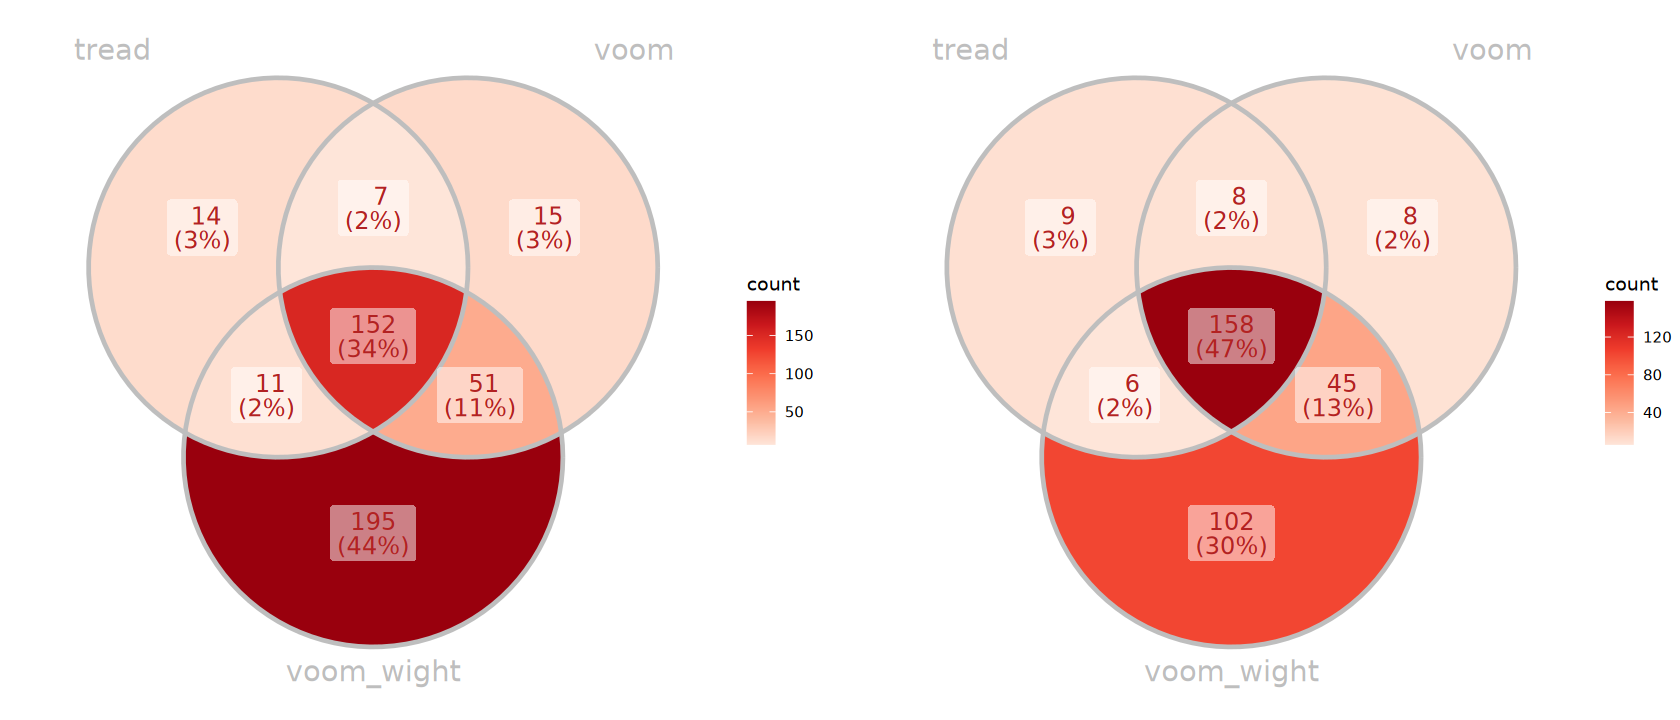

In [110]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [111]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [112]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

Warning message:
"Removed 19 rows containing non-finite outside the scale range (`stat_bin()`)."


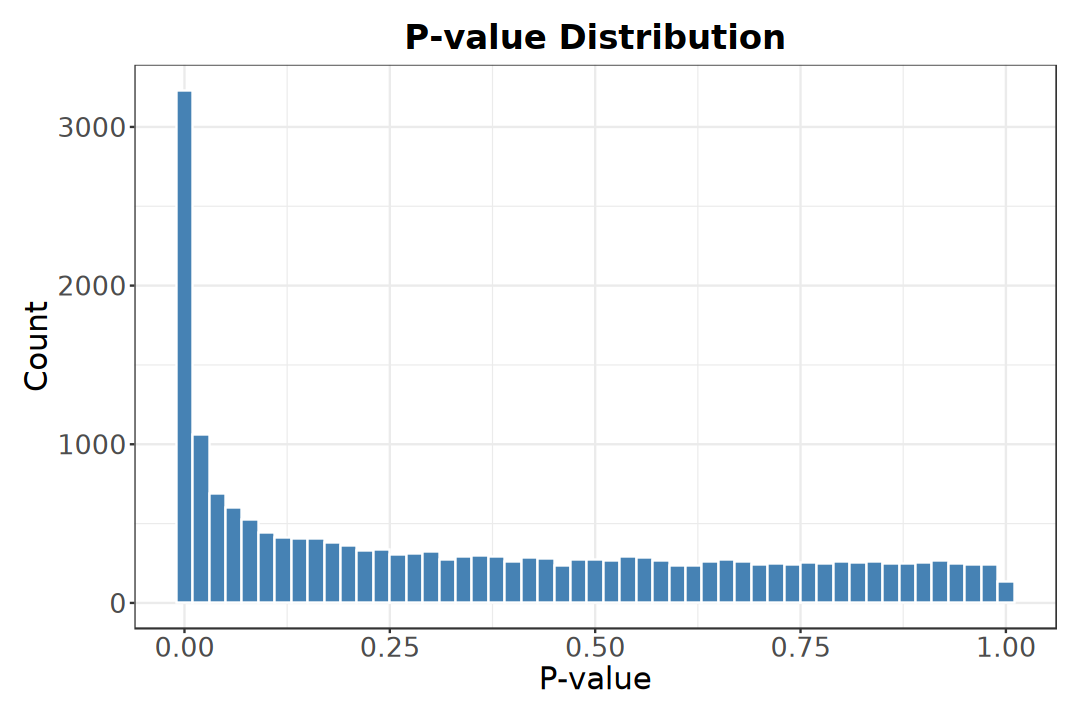

In [113]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [114]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [115]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

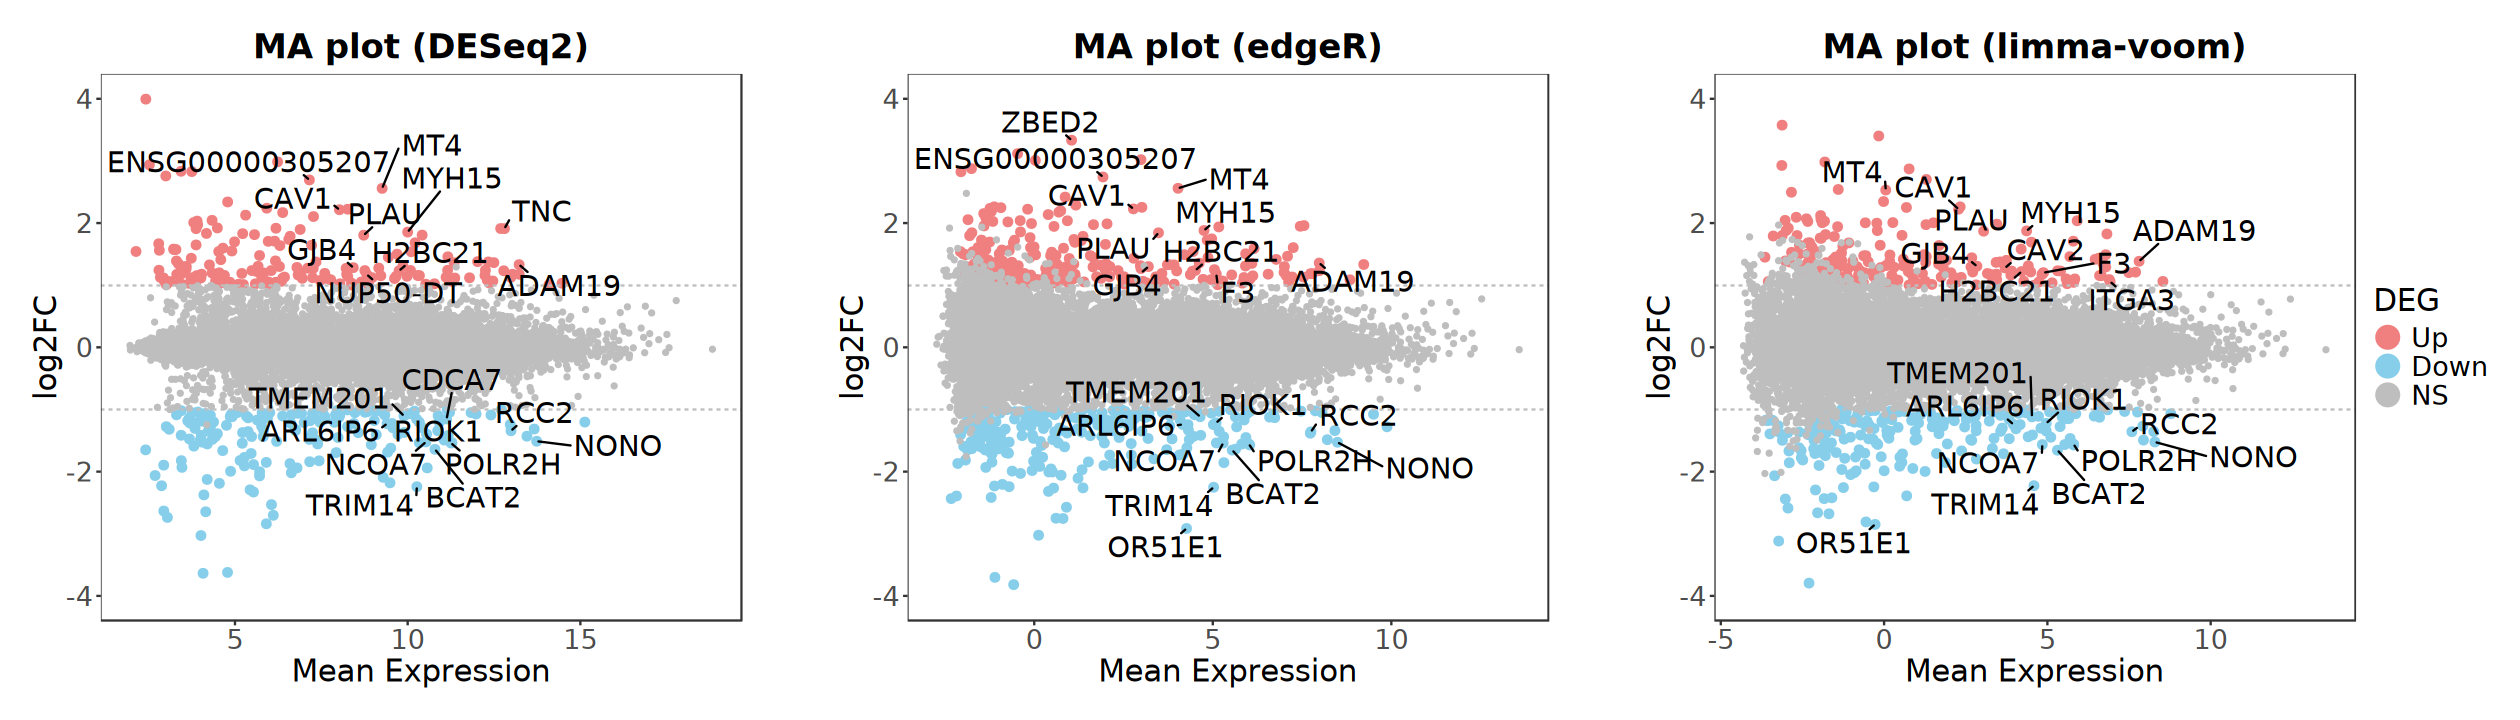

In [116]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [117]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [118]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

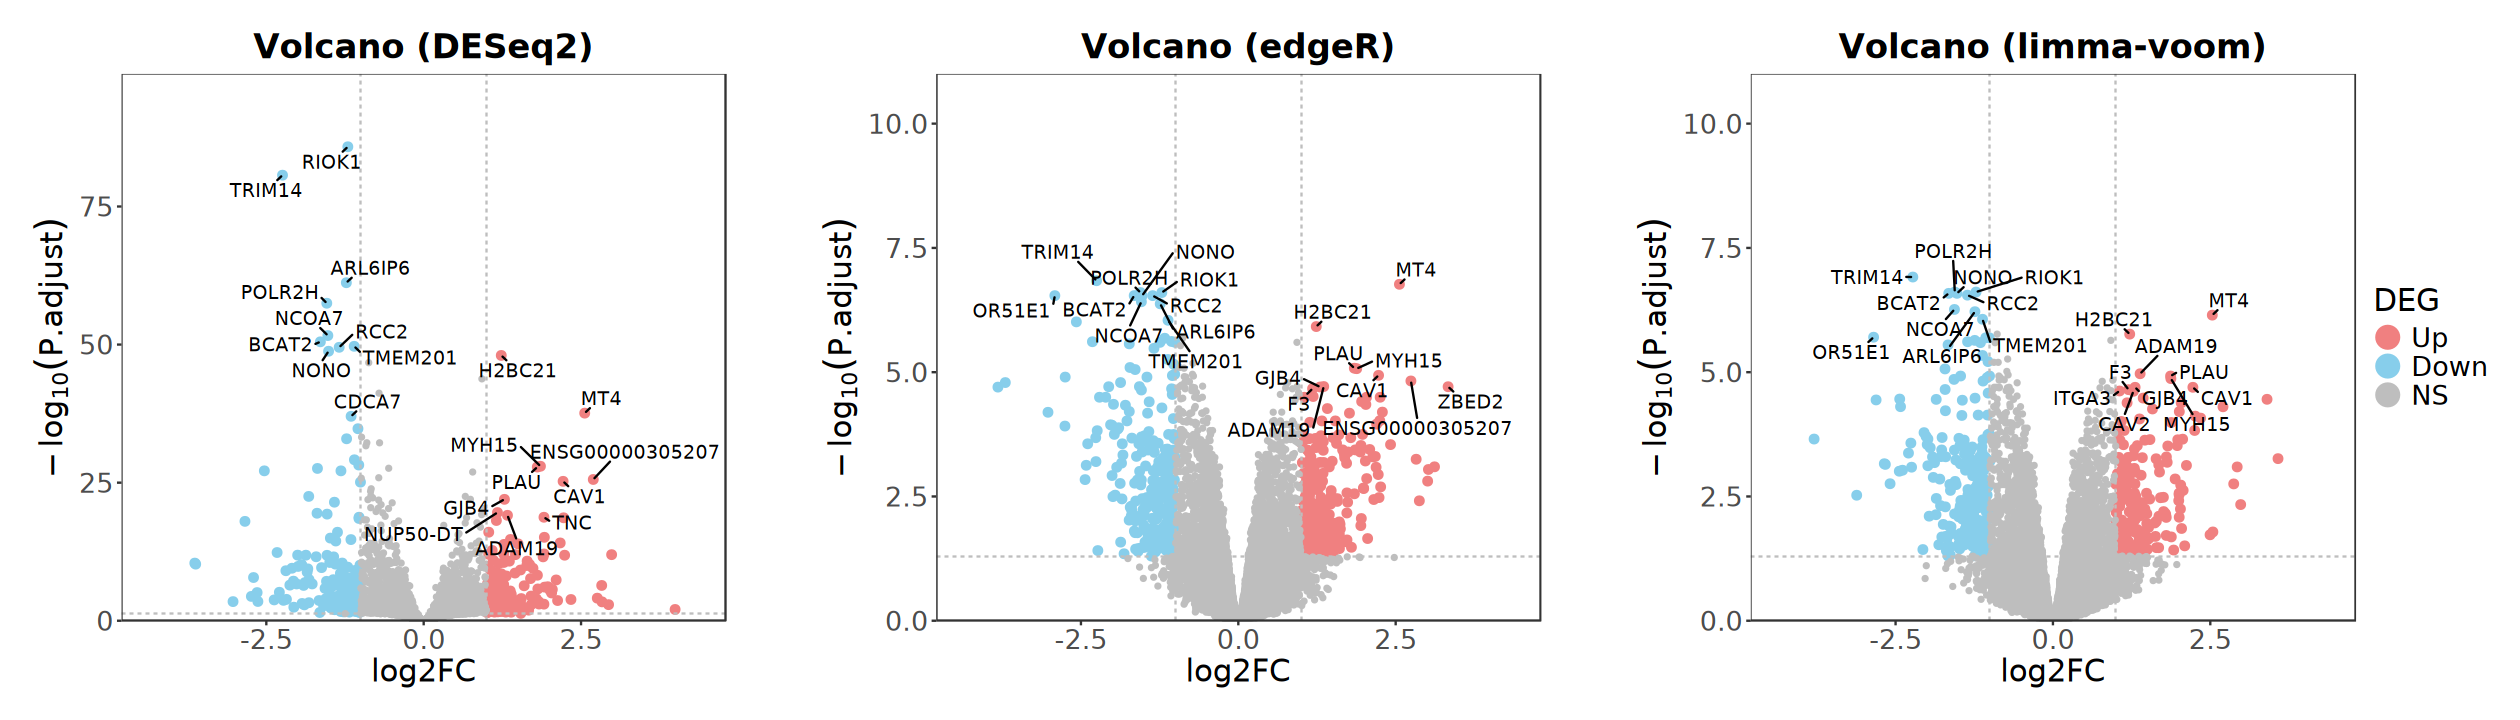

In [119]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [120]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [121]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [122]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

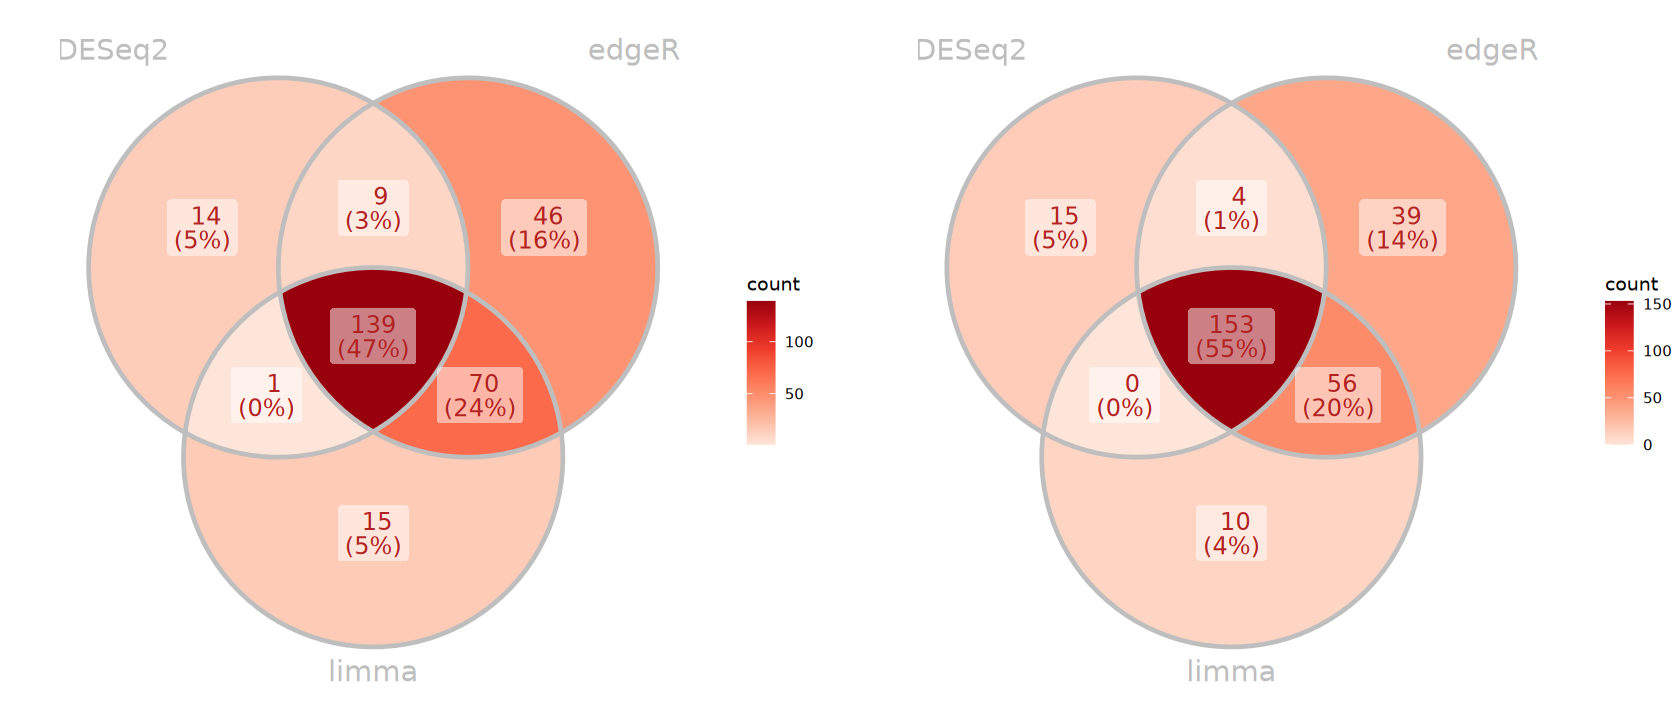

In [123]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [124]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."


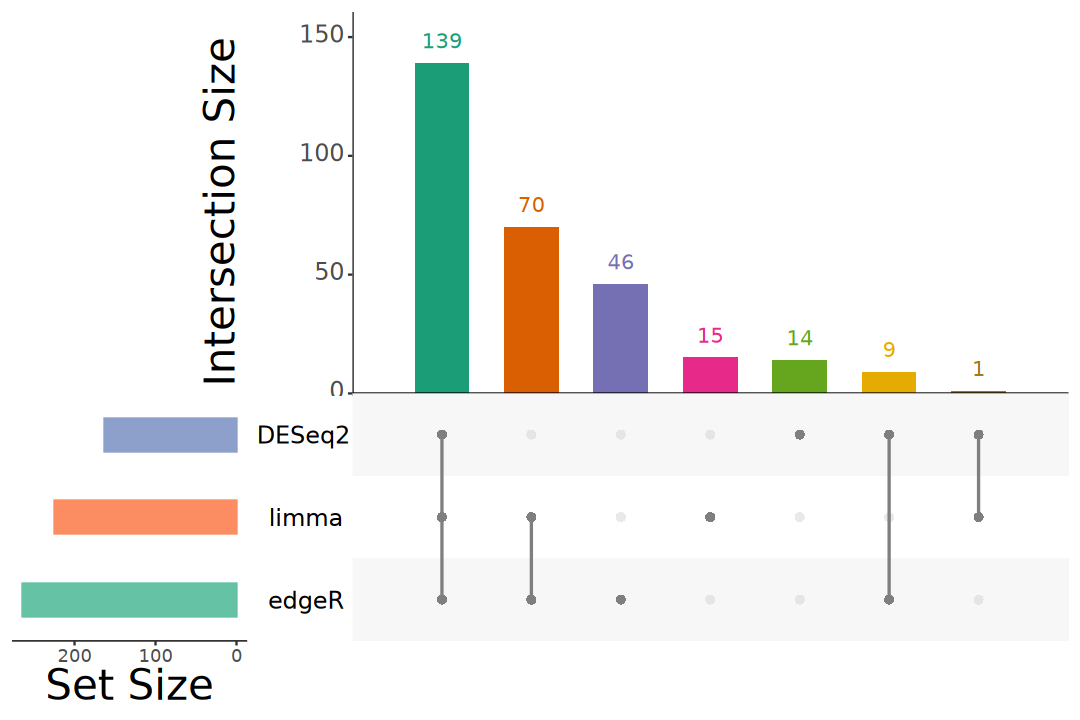

In [125]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

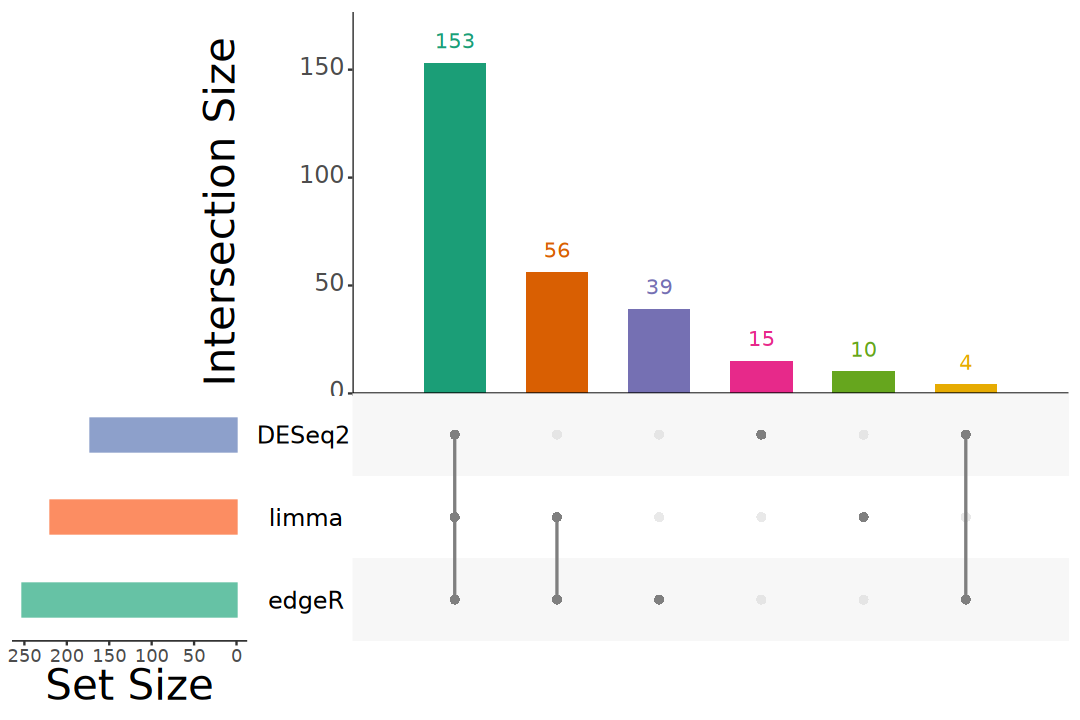

In [126]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [127]:
res_lfc <- lfcShrink(dds, coef = "Group_siFOXA1_vs_Control", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 19200 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1836, 9.6%
LFC < 0 (down)     : 1979, 10%
outliers [1]       : 19, 0.099%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [128]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  163   172 18865 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSG00000124784.9,1292.0130,-1.204794,0.06014610,7.978917e-91,1.530436e-86,Down,RIOK1,protein_coding,2940,RIOK1
ENSG00000106785.15,1230.3829,-2.242828,0.11590498,2.220827e-85,2.129884e-81,Down,TRIM14,protein_coding,5481,TRIM14
ENSG00000177917.12,675.9072,-1.228555,0.07247707,9.849049e-66,6.297153e-62,Down,ARL6IP6,protein_coding,19294,ARL6IP6
ENSG00000163882.10,2439.7149,-1.539253,0.09371093,6.779550e-62,3.250964e-58,Down,POLR2H,protein_coding,3154,POLR2H
ENSG00000111912.20,1475.9952,-1.522358,0.09770727,6.033399e-56,2.314532e-52,Down,NCOA7,protein_coding,7647,NCOA7
ENSG00000105552.15,1770.3058,-1.641002,0.10654057,9.796331e-55,3.131724e-51,Down,BCAT2,protein_coding,4553,NA


In [129]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

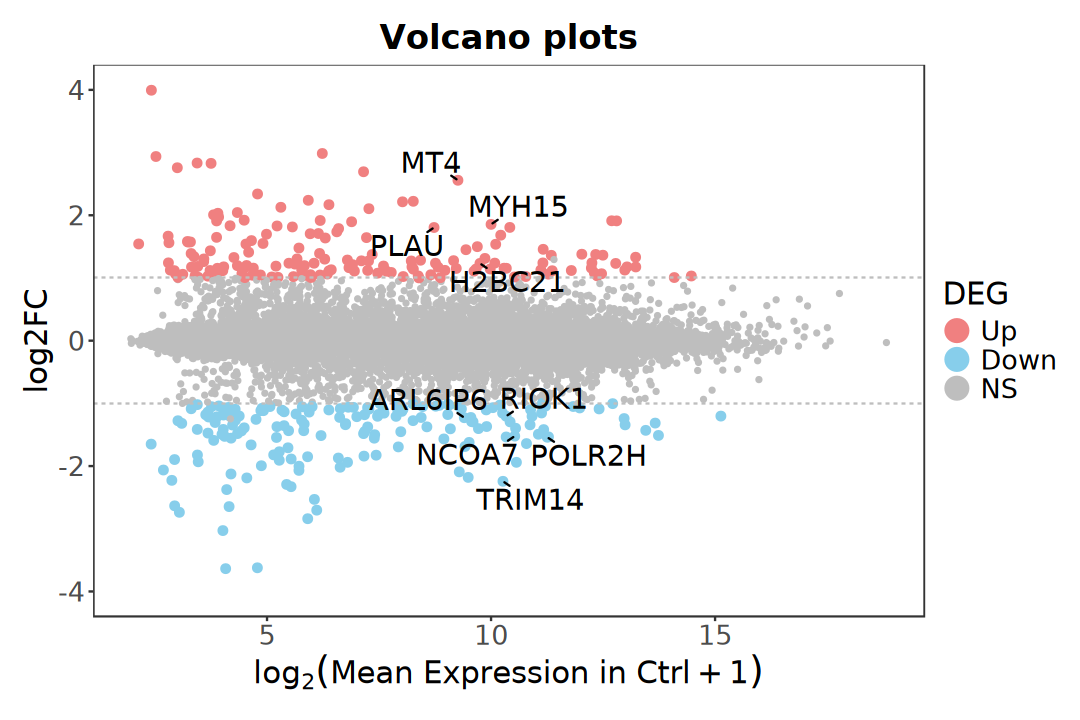

In [130]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [131]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [132]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [133]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [134]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

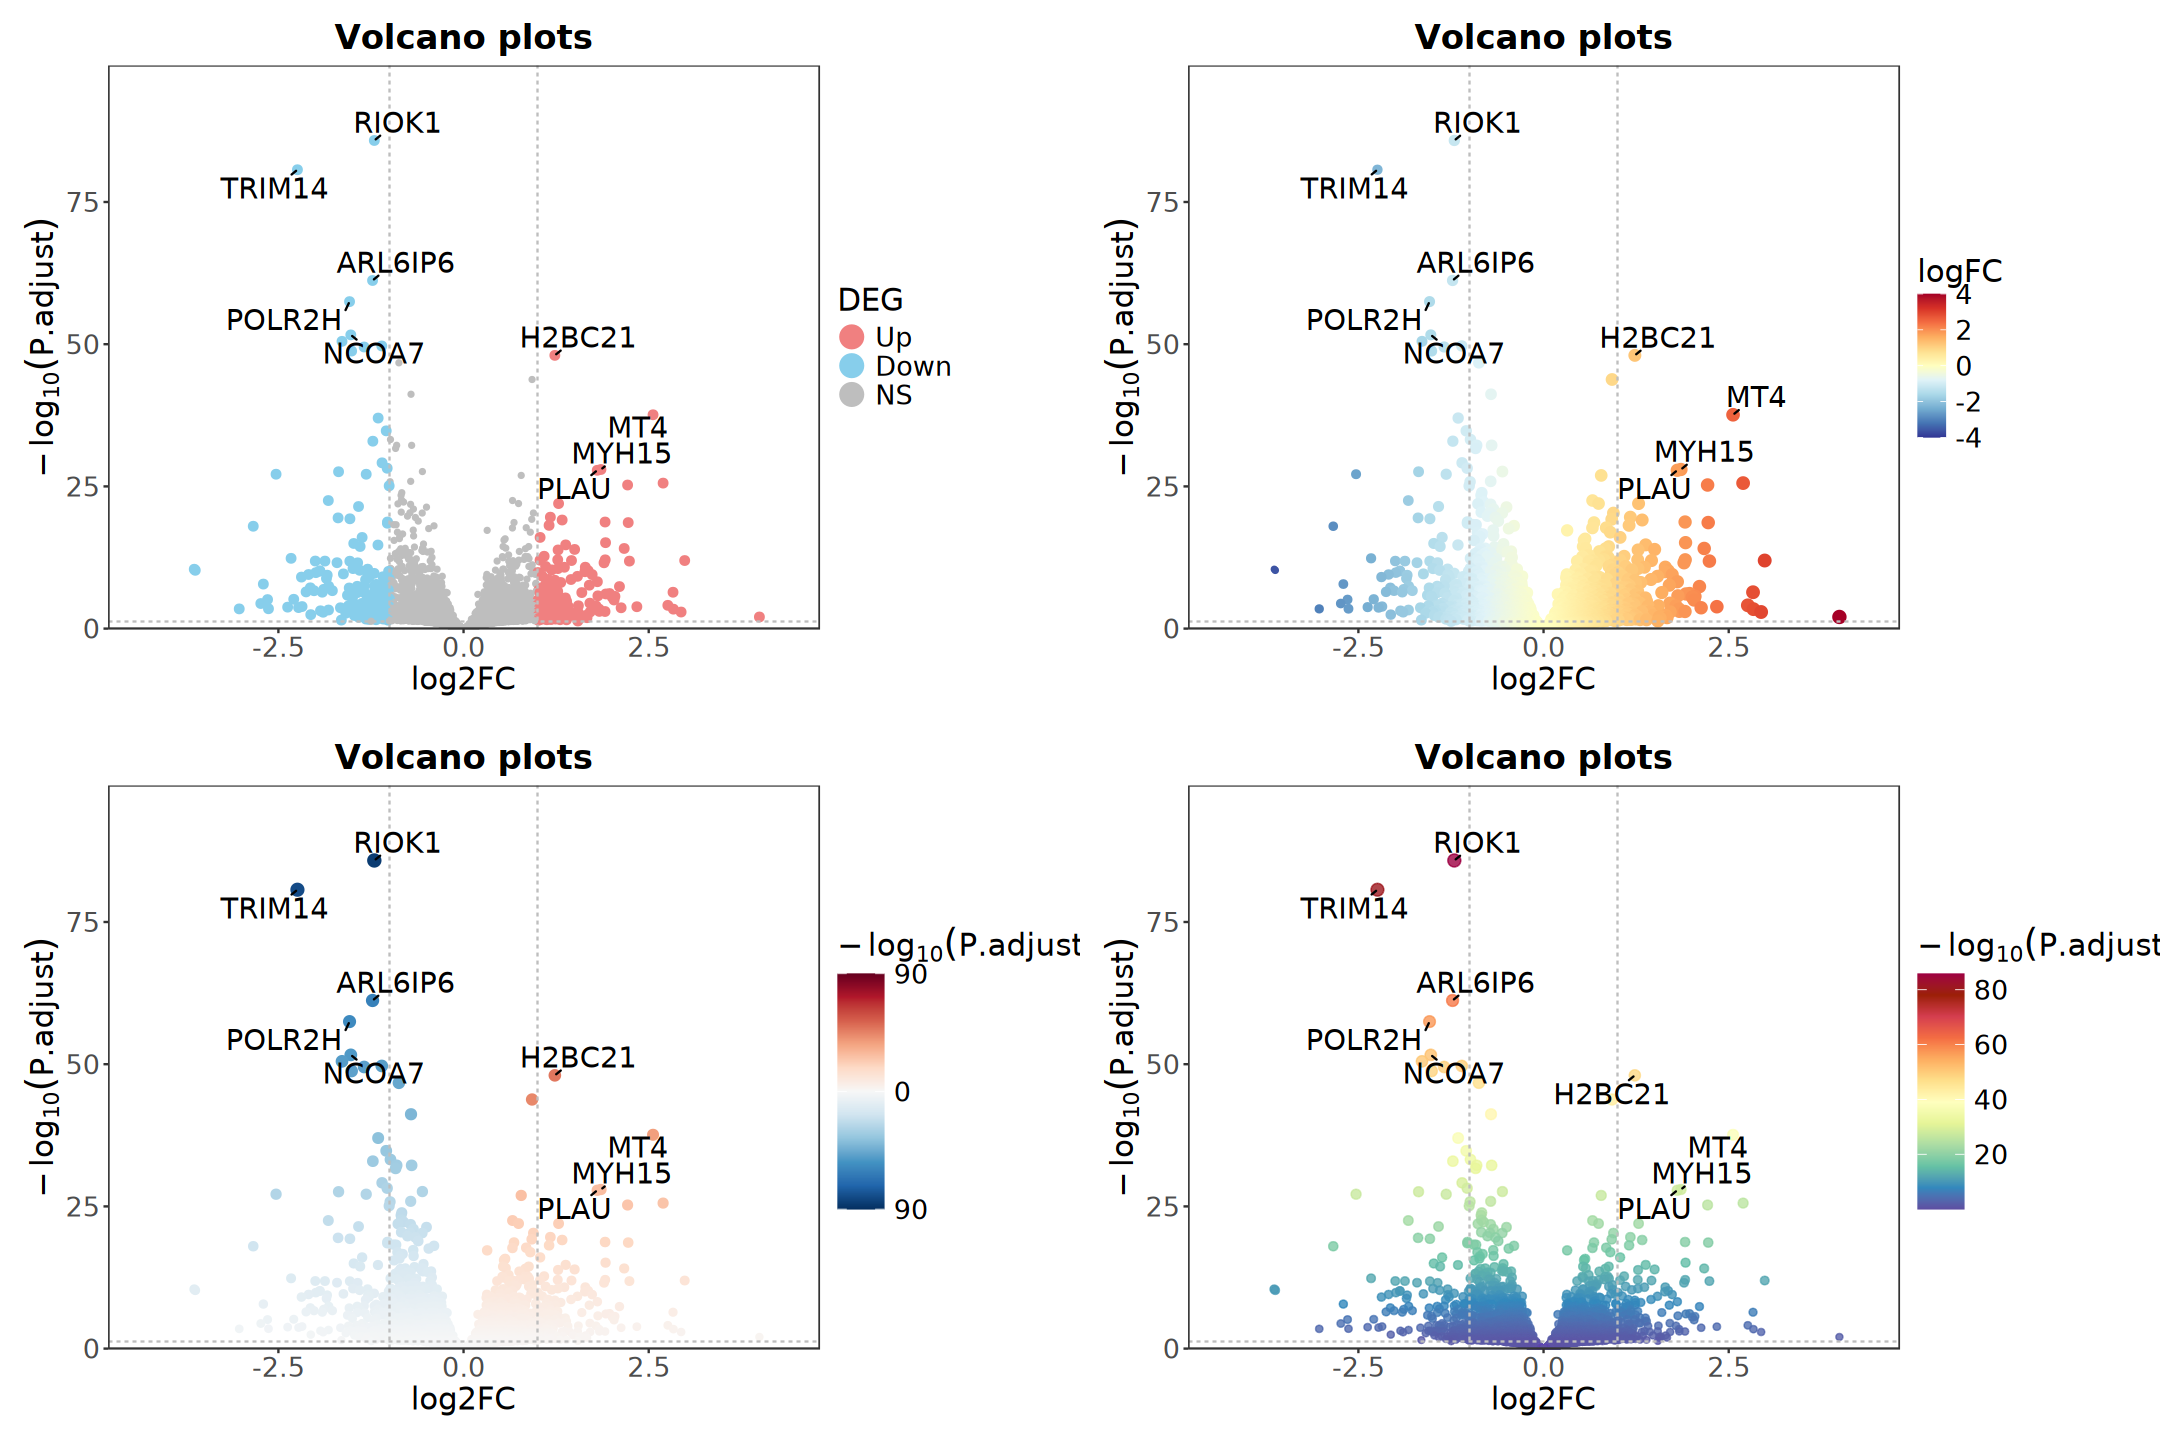

In [135]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [136]:
ctrl_samples <- colnames(dds)[dds$Group == "Control"]
treat_samples <- colnames(dds)[dds$Group == "siFOXA1"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [137]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

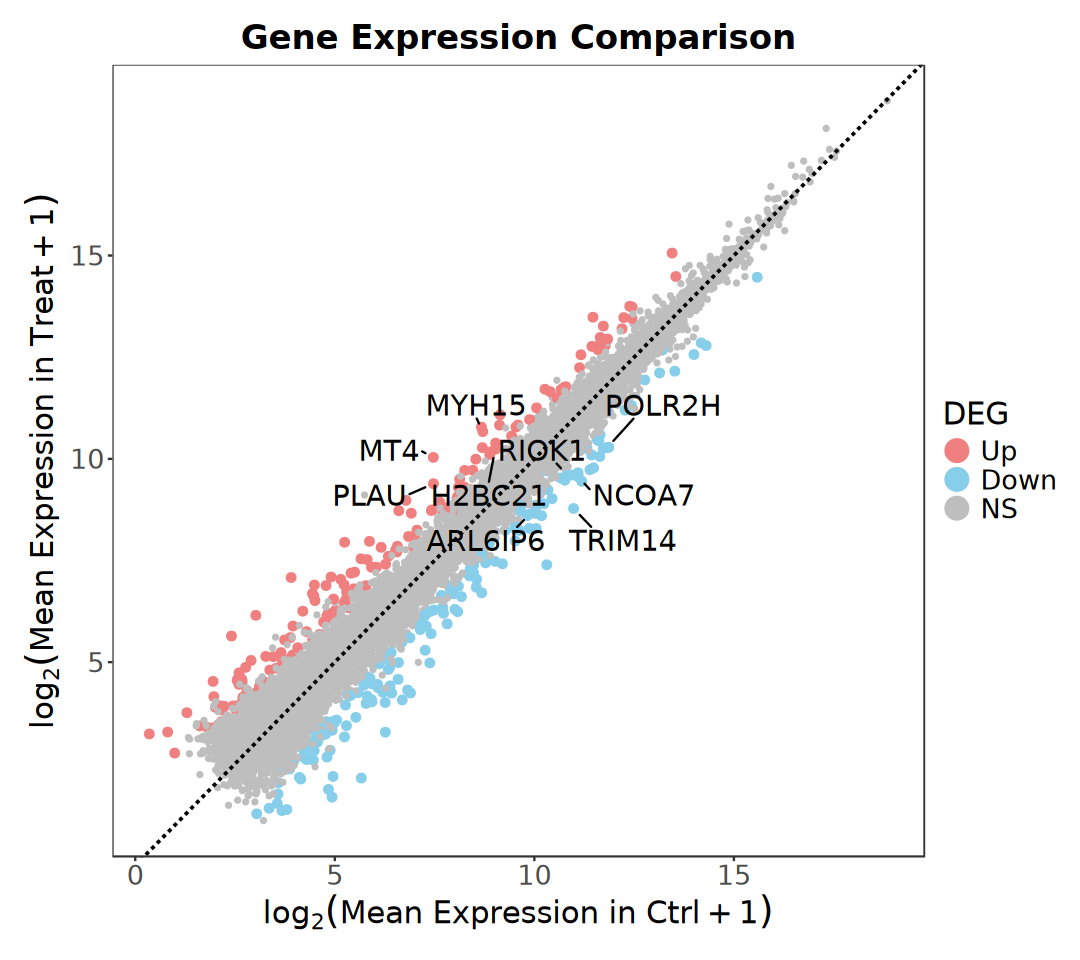

In [138]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [139]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [140]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group, Cell)

In [141]:
cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Cell = cell_colors, Group = group_colors, 
    Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

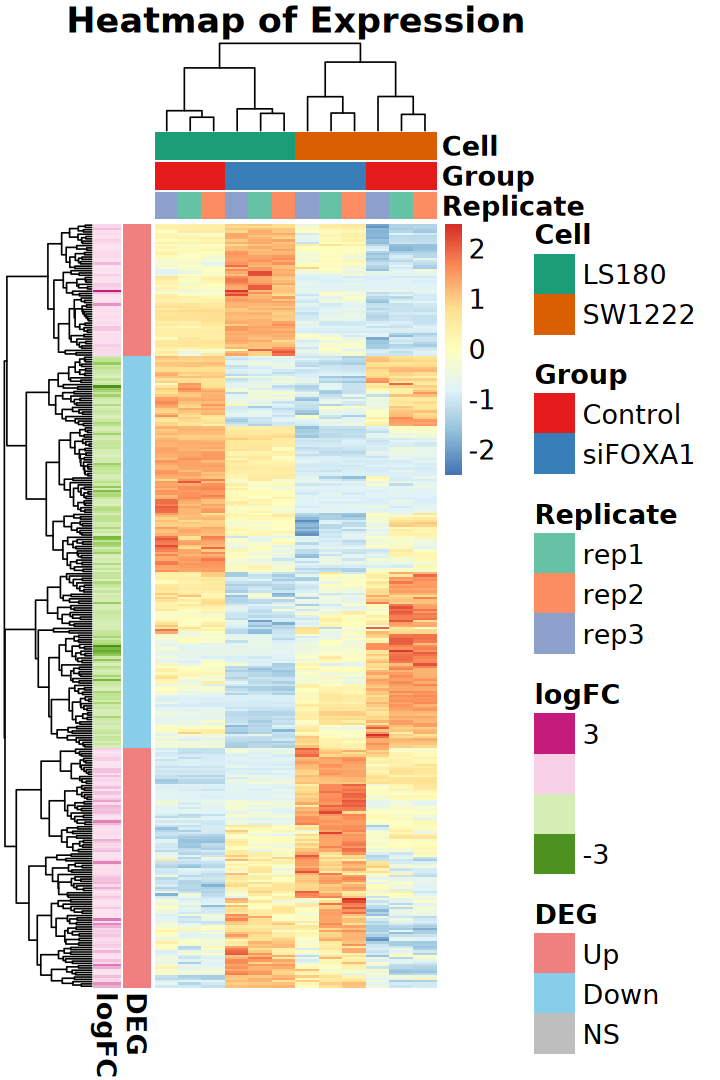

In [142]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [143]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

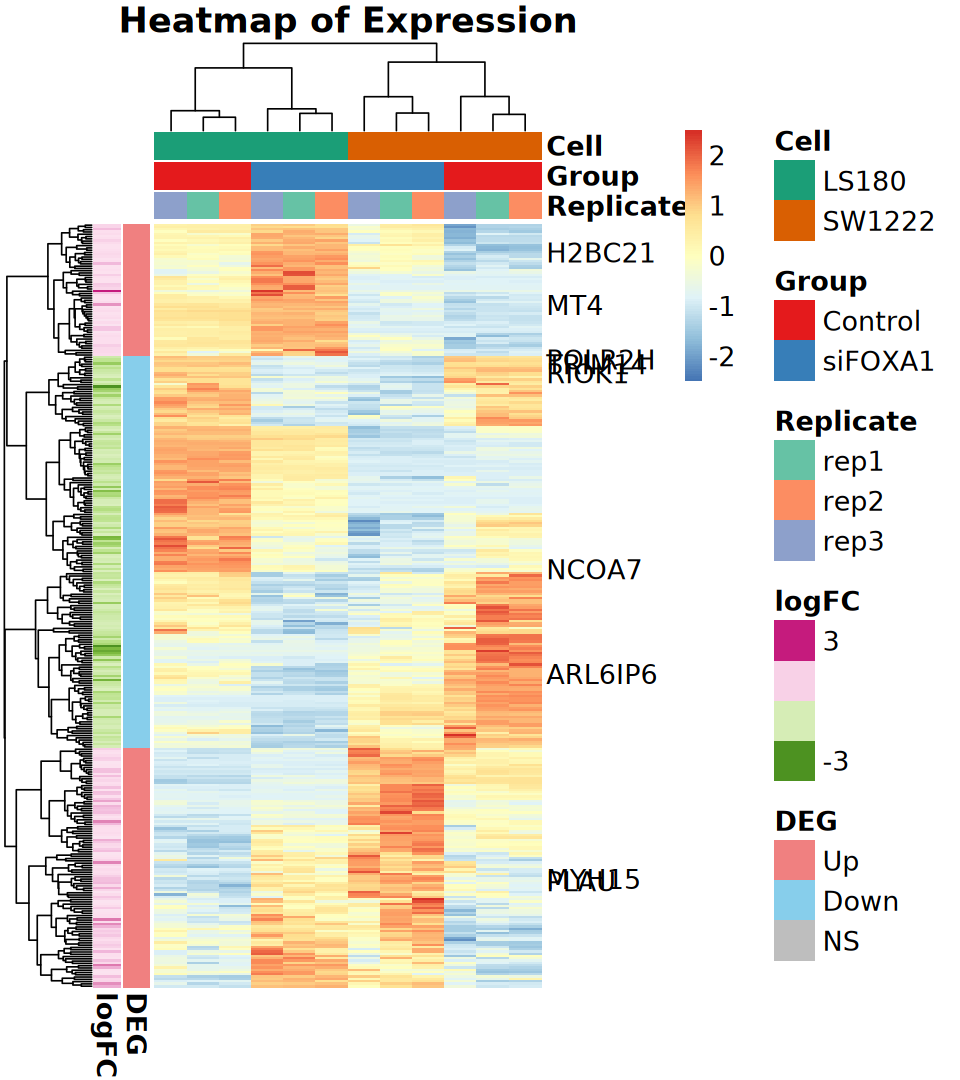

In [144]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [145]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [146]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [147]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [148]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Cell = cell_colors,
        Group = group_colors, 
        Status = replicate_colors))

In [149]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [150]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [151]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Group, Replicate)

In [152]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_cell <- Legend(
    title = "Cell", labels = levels(dds$Cell))
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_cell, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [153]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

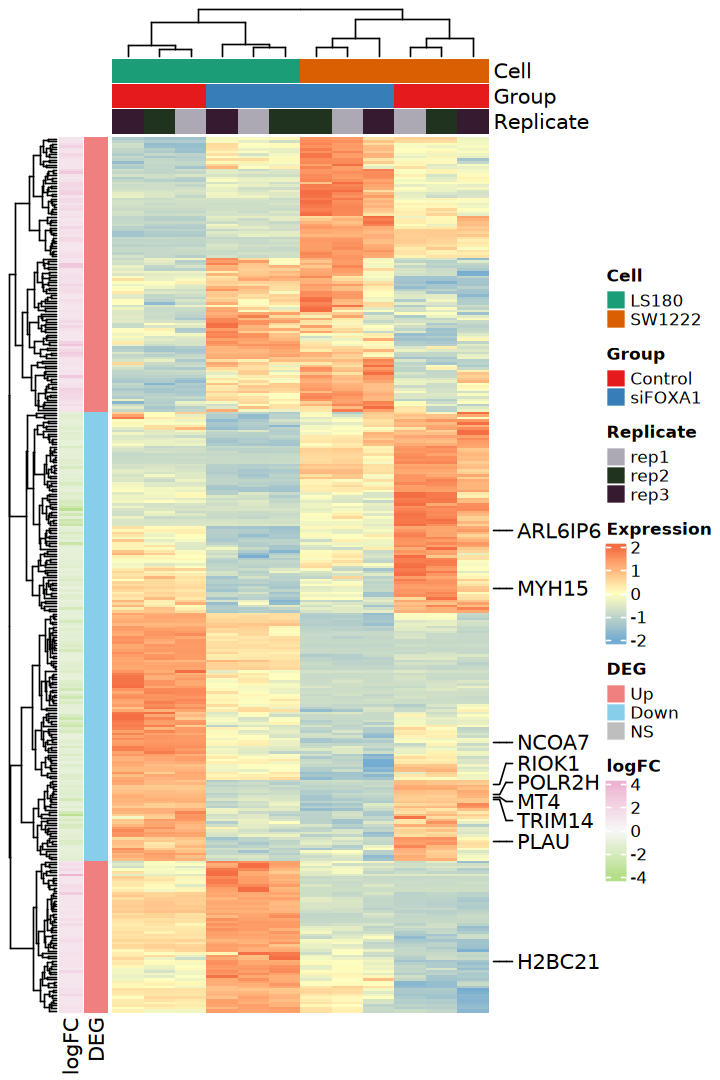

In [154]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [155]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [156]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [157]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"15.69% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.91% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.91% of input gene IDs are fail to map..."


In [158]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [159]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [160]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [161]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0043062,extracellular structure organization,11/108,231/12911,0.04761905,5.692681,6.609772,3.561280e-06,0.006199622,0.005321642,11
2,DESeq2-Up,BP,GO:0008544,epidermis development,12/108,301/12911,0.03986711,4.765965,6.071852,7.832568e-06,0.006199622,0.005321642,12
3,DESeq2-Up,BP,GO:0031424,keratinization,5/108,34/12911,0.14705882,17.580338,8.890877,8.559074e-06,0.006199622,0.005321642,5
4,DESeq2-Up,BP,GO:0061041,regulation of wound healing,7/108,96/12911,0.07291667,8.716917,6.970105,1.523753e-05,0.008277788,0.007105501,7
5,DESeq2-Up,BP,GO:0030198,extracellular matrix organization,10/108,230/12911,0.04347826,5.197665,5.899485,2.230209e-05,0.008384193,0.007196836,10
6,DESeq2-Up,BP,GO:0045229,external encapsulating structure organization,10/108,231/12911,0.04329004,5.175164,5.880836,2.315009e-05,0.008384193,0.007196836,10


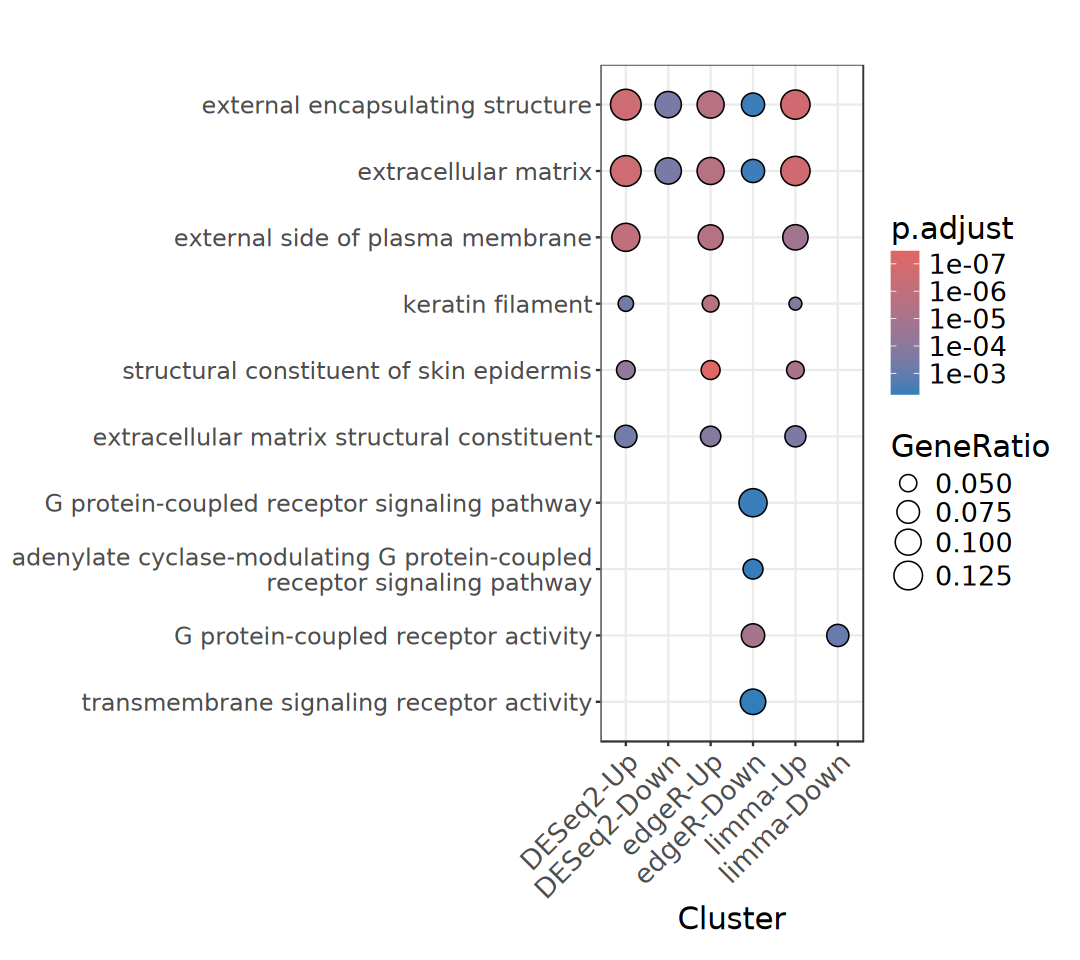

In [162]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [163]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [164]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"


In [165]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Organismal Systems,Development and regeneration,hsa04382,Cornified envelope formation,12/67,127/6328,0.09448819,8.924198,9.331270,5.953342e-09,7.560744e-07,6.830676e-07,12
2,edgeR-Up,Organismal Systems,Development and regeneration,hsa04382,Cornified envelope formation,19/97,127/6328,0.14960630,9.759883,12.441571,2.696645e-14,4.907894e-12,4.626875e-12,19
3,edgeR-Up,Human Diseases,Infectious disease: bacterial,hsa05150,Staphylococcus aureus infection,7/97,38/6328,0.18421053,12.017363,8.498652,1.368465e-06,1.245304e-04,1.173999e-04,7
4,edgeR-Up,Cellular Processes,Cellular community - eukaryotes,hsa04510,Focal adhesion,11/97,162/6328,0.06790123,4.429681,5.517157,3.272995e-05,1.985617e-03,1.871923e-03,11
5,edgeR-Down,Metabolism,Xenobiotics biodegradation and metabolism,hsa00980,Metabolism of xenobiotics by cytochrome P450,8/102,49/6328,0.16326531,10.128852,8.210382,9.029503e-07,2.013579e-04,1.843920e-04,8
6,edgeR-Down,Organismal Systems,Digestive system,hsa04976,Bile secretion,8/102,57/6328,0.14035088,8.707258,7.481064,2.974815e-06,3.316919e-04,3.037443e-04,8


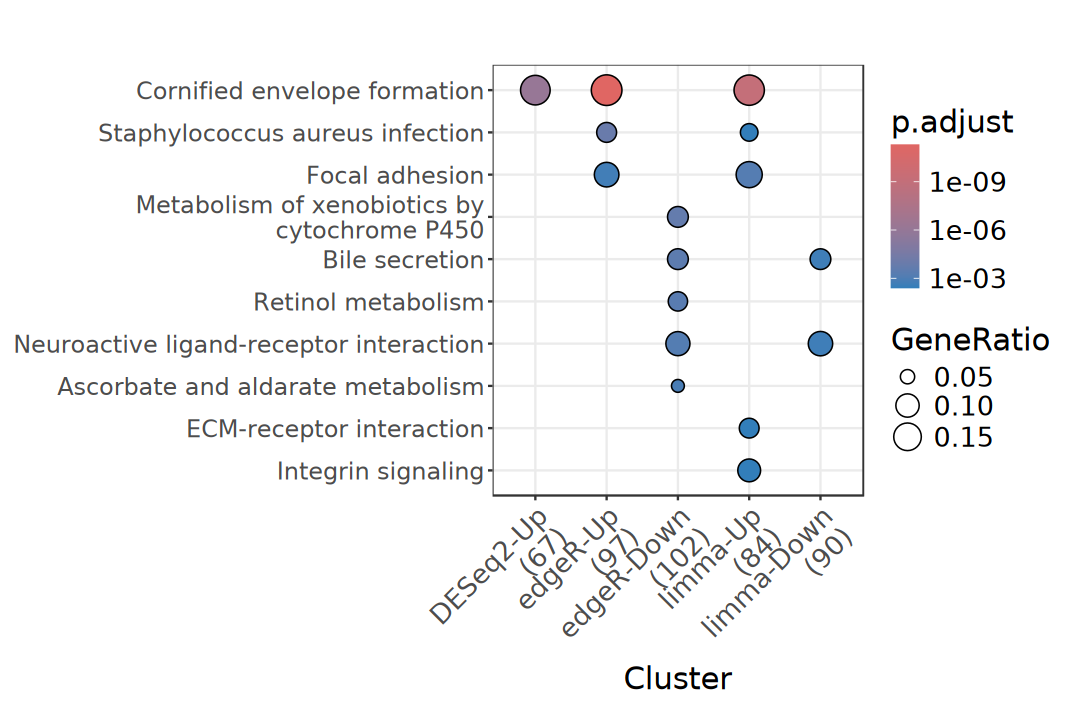

In [166]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)